# Selective early prediction of phage–bacteria dynamics with simulation-trained Transformer ensembles

This notebook reproduces the analyses of the accompanying simulation study. A vectorised two-phage chemostat solver, derived from the Cocktail model (Nilsson, *Viruses* 2022), generates labelled trajectories. Calibrated Transformer ensembles predict 24-hour outcomes from sparse, noisy, left-censored observations at 2, 4 and 6 h. A frozen selective policy is certified with exact one-sided binomial upper bounds and then stress-tested under assay, kinetic and latent-period mechanism shift. **All results are simulation-based; experimental validation is required before any biological or clinical use.**


## Cell 1: Setup, configuration and cohort design

This cell fixes everything that must be decided before any data are generated.

- **Determinism.** One global seed (`20261002`) is set for Python, NumPy and PyTorch. The cuBLAS workspace is fixed, TF32 and cuDNN benchmarking are off, and deterministic algorithms are requested. Results are expected to be bit-identical only on the same hardware and software stack.
- **Output folder.** All artefacts are written to `cocktail_master_v8/`, with subfolders `data`, `models`, `tables`, `figures` and `software`. The root is chosen automatically (Kaggle, Colab or the current directory).
- **Simulator prior.** `PARAMETERS` and `BOUNDS` define the 15 parameters of each simulated case, drawn uniformly from the stated ranges (initial density, growth rate, dilution rate, and for each phage the adsorption constant, latent period, burst size, mutation rate, decay rate and initial titre).
- **Cohorts and roles.** `COUNTS` and `COHORT_PLAN` assign every cohort a fixed role (training, selection and calibration, threshold tuning, lockbox, certification) and a unique seed. Seven stress cohorts of 10,000 cases apply pre-specified assay or kinetic perturbations (`SCENARIOS`).
- **Configuration and run identity.** `CFG` collects every setting that affects results (sampling schedule, assay noise, network width, loss weights, threshold grid, risk target and support gates). `RUN_ID` is the SHA-256 of `CFG`, and `config.json` is written once. If the configuration changes, the notebook stops and asks for a new output directory.
- **Reporting helpers.** `save_table` and `save_figure` write every table (CSV and LaTeX) and figure (PDF and PNG) with a registry, and the plotting style is set for publication.

**Outputs.** Table 1 (cohort design and seeds), Figure 1 (trajectory budget by cohort role), `config.json` and `environment.json`.

**Notes**
- The total printed here (310,000 trajectories) covers the development, certification and stress cohorts. The latent-period and matched-model cohorts, generated later, add 250,000 more.
- The fingerprint printed here is computed from the configuration only. The final run fingerprint, which also includes the solver digest, is printed in cell 2.
- Do not edit `CFG`, including its `version` label, after the first run. Any change alters the run fingerprint and invalidates all stored artefacts.

Figure font: Liberation Sans
Table 1: Cohort design and random seeds


,Cohort,Role,Trajectories,Seed,Perturbation
0,Training,Training,60000,20261000,none
1,Robust training,Training,30000,20261001,none
2,Validation,Selection and calibration,10000,20261002,none
3,Temperature calibration,Selection and calibration,10000,20261003,none
4,OOD calibration,Selection and calibration,10000,20261004,none
5,Policy tuning,Threshold tuning,30000,20261005,none
6,Policy lockbox,Locked-box test,30000,20261006,none
7,Certification,Certification,60000,20261007,none
8,Stress: reference,Stress test,10000,20262000,none
9,Stress: noise ×1.5,Stress test,10000,20262001,noise=1.5


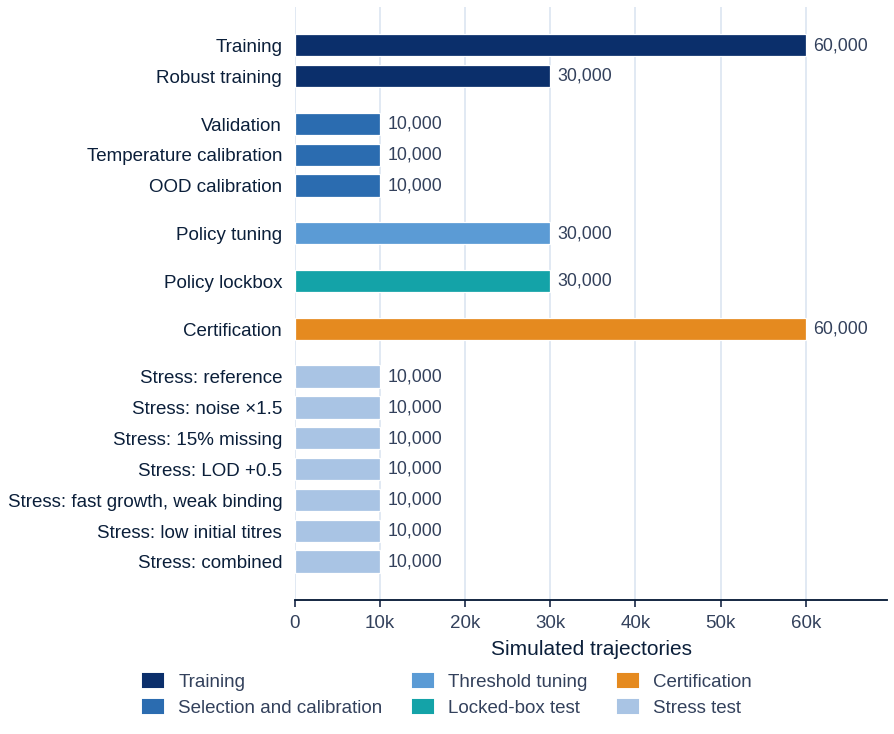

Figure 1: Trajectory budget by cohort role
Run fingerprint: cdb9553742f87c8a55e47797300f0fe2b5534c33c9dd8168c25756270e429fb0
Total trajectories: 310000 | Device: cuda | Output: /kaggle/working/cocktail_master_v8


In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import hashlib, json, math, platform, random, re, sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy.stats import beta
from sklearn.covariance import LedoitWolf
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             f1_score, log_loss, roc_auc_score)
from IPython.display import display

# ------------------------------------------------------------------ seeds
SEED = 20261002
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_default_dtype(torch.float32)
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.use_deterministic_algorithms(True, warn_only=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------------ paths
if Path("/kaggle/working").exists():
    BASE = Path("/kaggle/working")
elif Path("/content").exists():
    BASE = Path("/content")
else:
    BASE = Path.cwd()
ROOT = BASE / "cocktail_master_v8"
for sub in ("data", "models", "tables", "figures", "software"):
    (ROOT / sub).mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------------ design
PARAMETERS = [
    "log10_bacteria0", "growth_s_per_h", "log10_adsorption_a", "log10_adsorption_b",
    "latent_a_min", "latent_b_min", "burst_a", "burst_b", "log10_mutation_a",
    "log10_mutation_b", "flow_per_h", "phage_decay_a_per_h", "phage_decay_b_per_h",
    "log10_titre_a", "log10_titre_b",
]
BOUNDS = [[4, 8], [.2, 1.2], [-12, -8], [-12, -8], [10, 60], [10, 60], [10, 300], [10, 300],
          [-10, -5], [-10, -5], [0, .5], [0, .2], [0, .2], [5, 10], [5, 10]]
SCENARIOS = {
    "reference": {}, "noise_1p5x": {"noise": 1.5},
    "missing_15pct": {"missing": .15}, "lod_plus_0p5": {"lod_shift": .5},
    "high_growth_low_adsorption": {"kinetic_shift": True},
    "low_initial_titres": {"low_titre": True},
    "combined": {"noise": 1.5, "missing": .15, "lod_shift": .5,
                 "kinetic_shift": True, "low_titre": True},
}
COUNTS = {"train": 60000, "robust_train": 30000, "validation": 10000, "temperature": 10000,
          "ood_calibration": 10000, "policy_tuning": 30000, "policy_lockbox": 30000,
          "certification": 60000}
SEEDS = {name: 20261000 + i for i, name in enumerate(COUNTS)}
STRESS_SEED0 = 20262000
COHORT_PLAN = [{"name": n, "n": c, "seed": SEEDS[n], "scenario": {}} for n, c in COUNTS.items()]
COHORT_PLAN += [{"name": "stress_" + k, "n": 10000, "seed": STRESS_SEED0 + i, "scenario": s}
                for i, (k, s) in enumerate(SCENARIOS.items())]

CFG = {
    "version": "cocktail_master_v8", "seed": SEED, "parameters": PARAMETERS, "bounds": BOUNDS,
    "master_minutes": [0, 15, 30, 60, 90, 120, 180, 240, 360],
    "full_minutes": list(range(0, 1441, 15)), "hours": [2., 4., 6.], "allowed_classes": [3, 1, 1],
    "outcomes": ["sustained_clearance", "rebound", "partial_control", "failure_or_persistence"],
    "channels": ["total_bacteria", "phage_A", "phage_B"],
    "log10_lod": [0., 0., 0.], "sigma_log10": [.15, .15, .15],
    "shard_size": 512, "train_batch": 256, "inference_batch": 512,
    "epochs": 180, "patience": 20, "learning_rate": 3e-4, "width": 72, "mixture_components": 5,
    "endpoint_loss_weight": .25, "action_loss_weight": 1.0, "ranking_loss_weight": .25,
    "ood_quantile": .975, "risk_target": .10, "minimum_action_support": 300,
    "minimum_coverage": .05, "lockbox_minimum_coverage": .055, "tuning_precision": .945,
    "threshold_grid": np.linspace(.70, .995, 60).tolist(), "cohorts": COHORT_PLAN,
    "simulator": "v8_cohort_queue_superinfection",
    "training_augmentation_fraction": .35, "robust_training_augmentation_fraction": .65,
    "action_ensemble_size": 3, "feature_dims": [19, 19, 19],
    "baseline_measurement_forced_present": False,
}

# ------------------------------------------------------------------ io helpers
def write_json(path, obj):
    path = Path(path); tmp = path.with_suffix(path.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=2, allow_nan=False)); tmp.replace(path)

def save_pt(path, obj):
    path = Path(path); tmp = path.with_suffix(".tmp")
    torch.save(obj, tmp); tmp.replace(path)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

RUN_ID = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode()).hexdigest()
CONFIG_PATH = ROOT / "config.json"
if CONFIG_PATH.exists():
    assert json.loads(CONFIG_PATH.read_text()) == json.loads(json.dumps(CFG)), \
        "Configuration changed. Use a new output directory."
else:
    write_json(CONFIG_PATH, CFG)
write_json(ROOT / "environment.json", dict(
    python=platform.python_version(), torch=str(torch.__version__), numpy=np.__version__,
    pandas=pd.__version__, matplotlib=mpl.__version__, device=str(DEVICE), run_id=RUN_ID))

# ------------------------------------------------------------------ publication style
from matplotlib import font_manager as fm

def pick_font(candidates):
    for name in candidates:
        try:
            fm.findfont(name, fallback_to_default=False)
            return name
        except Exception:
            continue
    return "DejaVu Sans"

FONT = pick_font(["Inter", "Source Sans 3", "Helvetica Neue", "Helvetica",
                  "Arial", "Liberation Sans", "DejaVu Sans"])

BLUE = {
    "ink": "#0B1F3A", "navy": "#0B2F6B", "deep": "#124A9C", "mid": "#2B6CB0",
    "sky": "#5B9BD5", "pale": "#A9C4E4", "mist": "#E6EEF8",
    "grid": "#DCE5F1", "text": "#33415C",
}
ACCENT = {"teal": "#14A3A8", "amber": "#E58A1F", "rose": "#C2455A"}
PALETTE = {
    "bacteria": BLUE["deep"], "phage_a": ACCENT["amber"], "phage_b": ACCENT["teal"],
    "sustained_clearance": BLUE["mid"], "rebound": ACCENT["amber"],
    "partial_control": BLUE["pale"], "failure_or_persistence": BLUE["navy"],
    **BLUE, **ACCENT,
}
FIG_W1, FIG_W2 = 3.5, 7.2

mpl.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": [FONT, "DejaVu Sans"],
    "font.size": 9, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.fontsize": 9, "axes.titlesize": 10,
    "text.color": BLUE["text"], "axes.labelcolor": BLUE["ink"],
    "xtick.color": BLUE["text"], "ytick.color": BLUE["ink"],
    "axes.edgecolor": BLUE["ink"], "axes.linewidth": 0.9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "grid.color": BLUE["grid"], "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "xtick.direction": "out", "ytick.direction": "out",
    "xtick.major.width": 0.9, "ytick.major.width": 0.9,
    "xtick.major.size": 3.5, "ytick.major.size": 3.5,
    "lines.linewidth": 1.8, "lines.markersize": 5,
    "axes.prop_cycle": mpl.cycler(color=[BLUE["deep"], ACCENT["amber"], ACCENT["teal"],
                                         BLUE["sky"], BLUE["navy"], ACCENT["rose"]]),
    "legend.frameon": False,
    "figure.dpi": 150, "savefig.dpi": 600, "savefig.bbox": "tight", "savefig.pad_inches": 0.05,
    "pdf.fonttype": 42, "ps.fonttype": 42, "svg.fonttype": "none",
    "figure.constrained_layout.use": True,
    "mathtext.fontset": "dejavusans",
})
print("Figure font:", FONT)

FIG_REGISTRY, TAB_REGISTRY = [], []

def _slug(text):
    return re.sub(r"[^A-Za-z0-9]+", "_", text).strip("_")

def new_figure(width=FIG_W1, height=2.7):
    fig, ax = plt.subplots(figsize=(width, height))
    return fig, ax

def save_figure(fig, number, name, show=True):
    stem = f"Figure_{number:02d}_{_slug(name)}"
    for ext in ("pdf", "png"):
        fig.savefig(ROOT / "figures" / f"{stem}.{ext}", format=ext)
    FIG_REGISTRY.append({"figure": number, "name": name, "file_stem": stem})
    pd.DataFrame(FIG_REGISTRY).to_csv(ROOT / "tables" / "figure_registry.csv", index=False)
    if show:
        plt.show()
    plt.close(fig)
    print(f"Figure {number}: {name}")

def save_table(df, number, name, show=True, float_format="%.4g"):
    stem = f"Table_{number:02d}_{_slug(name)}"
    df.to_csv(ROOT / "tables" / f"{stem}.csv", index=False)
    try:
        (ROOT / "tables" / f"{stem}.tex").write_text(
            df.to_latex(index=False, float_format=lambda x: float_format % x, escape=True))
    except Exception as exc:
        print("LaTeX export skipped:", exc)
    TAB_REGISTRY.append({"table": number, "name": name, "file_stem": stem})
    pd.DataFrame(TAB_REGISTRY).to_csv(ROOT / "tables" / "table_registry.csv", index=False)
    if show:
        print(f"Table {number}: {name}")
        display(df)

# ------------------------------------------------------------------ step result 1
PRETTY = {
    "train": "Training", "robust_train": "Robust training", "validation": "Validation",
    "temperature": "Temperature calibration", "ood_calibration": "OOD calibration",
    "policy_tuning": "Policy tuning", "policy_lockbox": "Policy lockbox",
    "certification": "Certification",
    "stress_reference": "Stress: reference", "stress_noise_1p5x": "Stress: noise \u00d71.5",
    "stress_missing_15pct": "Stress: 15% missing", "stress_lod_plus_0p5": "Stress: LOD +0.5",
    "stress_high_growth_low_adsorption": "Stress: fast growth, weak binding",
    "stress_low_initial_titres": "Stress: low initial titres",
    "stress_combined": "Stress: combined",
}
ROLE = {"train": "Training", "robust_train": "Training",
        "validation": "Selection and calibration", "temperature": "Selection and calibration",
        "ood_calibration": "Selection and calibration", "policy_tuning": "Threshold tuning",
        "policy_lockbox": "Locked-box test", "certification": "Certification"}
ROLE_ORDER = ["Training", "Selection and calibration", "Threshold tuning",
              "Locked-box test", "Certification", "Stress test"]
ROLE_COLOR = dict(zip(ROLE_ORDER, [BLUE["navy"], BLUE["mid"], BLUE["sky"],
                                   ACCENT["teal"], ACCENT["amber"], BLUE["pale"]]))

rows = []
for c in COHORT_PLAN:
    rows.append({"Cohort": PRETTY[c["name"]], "Role": ROLE.get(c["name"], "Stress test"),
                 "Trajectories": c["n"], "Seed": c["seed"],
                 "Perturbation": ", ".join(f"{k}={v}" for k, v in c["scenario"].items()) or "none"})
DESIGN = pd.DataFrame(rows)
save_table(DESIGN, 1, "Cohort design and random seeds")

# y positions with a gap between role groups
ypos, y, prev = [], 0.0, None
for role in DESIGN["Role"]:
    if prev is not None and role != prev:
        y += 0.55
    ypos.append(y); y += 1.0; prev = role
ypos = np.array(ypos)

fig, ax = new_figure(FIG_W1 * 1.7, 4.9)
vals = DESIGN["Trajectories"].to_numpy()
ax.barh(ypos, vals, height=0.72, color=[ROLE_COLOR[r] for r in DESIGN["Role"]],
        edgecolor="white", linewidth=0.6, zorder=3)
for yy, v in zip(ypos, vals):
    ax.text(v + vals.max() * 0.015, yy, f"{v:,}", va="center", ha="left",
            fontsize=8.5, color=BLUE["text"])
ax.set_yticks(ypos)
ax.set_yticklabels(DESIGN["Cohort"])
ax.invert_yaxis()
ax.tick_params(axis="y", length=0, pad=6)
ax.set_xlim(0, vals.max() * 1.16)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{int(x/1000)}k" if x else "0"))
ax.grid(axis="x", zorder=0)
ax.spines["left"].set_visible(False)
ax.set_xlabel("Simulated trajectories")
handles = [plt.Rectangle((0, 0), 1, 1, color=ROLE_COLOR[r]) for r in ROLE_ORDER]
try:
    fig.legend(handles, ROLE_ORDER, loc="outside lower center", ncol=3,
               handlelength=1.1, columnspacing=1.6)
except Exception:
    ax.legend(handles, ROLE_ORDER, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
save_figure(fig, 1, "Trajectory budget by cohort role")

print("Run fingerprint:", RUN_ID)
print("Total trajectories:", int(DESIGN["Trajectories"].sum()), "| Device:", DEVICE, "| Output:", ROOT)

## Cell 2: Solver source, freeze and run fingerprint

This cell defines the vectorised two-phage chemostat solver and every function that depends on it. The code is stored as a text string (`RUNTIME_SOURCE`) and written to `software/cocktail_core.py`, so that the exact source can be hashed and archived. It is then imported as the module `core`.

**What the module contains**

- **`simulate`** is the mechanistic solver, a new vectorised PyTorch implementation derived from the Cocktail model. It integrates a batch of parameter sets in parallel by explicit Euler steps (default step 1 min). It includes Monod nutrient-limited growth with resource depletion, resistant host classes (to phage A, phage B, or both), deterministic mutation, delayed lysis implemented as queues of infected cells, phage decay and washout, and superinfection between the two phages. Latent periods are rounded to whole minutes between 10 and 60.
- **`outcomes`** assigns each noise-free trajectory to one of four outcomes: sustained clearance, rebound, partial control, or failure or persistence.
- **`schedule_mask`** and **`observe`** implement the sparse assay model: measurement times, noise, missingness, left-censoring at the limit of detection, and bounded augmentation for training cohorts.
- **`features`** builds the 19 features per time point used by the networks.
- **`Model`** is the Transformer encoder (two layers, four heads, width 72) with a four-class outcome head, a five-component mixture density head for the 24 h endpoint, and a binary action head.
- **`mixture_nll`** is the mixture-density loss, and **`cascade`** applies the sequential selective policy (call failure or persistence at 2 h, rebound at 4 or 6 h, otherwise abstain).

**Freezing and run fingerprint**

- `CORE_SHA` is the SHA-256 digest of the solver file. The run fingerprint (`RUN_ID`) is now computed from the configuration **and** the solver digest, so it changes if either changes.
- With `FREEZE_SOLVER = True`, a manifest (`software/manifest.json`) records the fingerprint. Any later edit to the solver or the configuration raises an error. The solver must be frozen before the certification cohort is generated.
- `environment.json` is rewritten with the package versions, the device and the solver digest.

**Output.** `software/cocktail_core.py`, `software/manifest.json`, `environment.json`, and the printed solver digest and run fingerprint. The values reported in the paper start with `71e958153f6492ce` (solver) and `646436dc7a6fbf7e` (run fingerprint).

**Notes**
- The text inside `RUNTIME_SOURCE`, including comments, is part of the hash. Do not edit it after the run.
- This fingerprint supersedes the configuration-only fingerprint printed in cell 1.

In [ ]:
RUNTIME_SOURCE = r'''
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F

def schedule_mask(minutes,hour):
    t=torch.as_tensor(minutes)
    mask=(t<=hour*60)[:,None].expand(-1,3).clone()
    phage=((t==0)|(t==120)|(t==360))&(t<=hour*60)
    mask[:,1:]=phage[:,None]
    return mask

def outcomes(full,minutes):
    b=full[:,:,0]; late=torch.as_tensor(minutes)>=21*60
    sustained=b[:,late].amax(1)<=0.
    rebound=(b.amin(1)<=0.)&(b[:,-1]>=2.)&~sustained
    partial=(b[:,0]-b[:,-1]>=2.)&~sustained&~rebound
    y=torch.full((len(b),),3,dtype=torch.long)
    y[sustained]=0; y[rebound]=1; y[partial]=2
    return y

def observe(clean,cfg,seed,scenario=None,augmented=False):
    scenario=scenario or {}; g=torch.Generator().manual_seed(int(seed)); n=len(clean)
    if augmented:
        # Most cases remain nominal. a fixed subset receives bounded assay augmentation.
        use=(torch.rand(n,1,1,generator=g)<float(cfg['training_augmentation_fraction'])).float()
        noise=1.+use*.5*torch.rand(n,1,1,generator=g)
        missing=.05+use*.10*torch.rand(n,1,1,generator=g)
        shift=use*.5*torch.rand(n,1,1,generator=g)
    else:
        noise=float(scenario.get('noise',1.))
        missing=float(scenario.get('missing',.05))
        shift=float(scenario.get('lod_shift',0.))
    lod=(torch.tensor(cfg['log10_lod']).view(1,1,3)+shift).expand(n,clean.shape[1],3).clone()
    sigma=torch.tensor(cfg['sigma_log10']).view(1,1,3)
    latent=clean+torch.randn(clean.shape,generator=g)*sigma*noise
    observed=torch.rand(clean.shape,generator=g)>=missing
    censored=observed&(latent<=lod)
    values=torch.where(observed,torch.maximum(latent,lod),torch.zeros_like(latent))
    return dict(values=values,observed=observed,censored=censored,lod=lod)

def features(obs,cfg,hour,mean,std):
    available=schedule_mask(cfg['master_minutes'],hour)[None]
    seen=obs['observed']&available; cens=obs['censored']&seen
    z=(obs['values']-mean[None,None])/std[None,None]
    z=torch.where(seen,z,torch.zeros_like(z))
    lod=(obs['lod']-mean[None,None])/std[None,None]
    lod=torch.where(available,lod,torch.zeros_like(lod))
    t=(torch.tensor(cfg['master_minutes']).float()/360.)[None,:,None].expand(len(z),-1,-1)
    base=torch.cat((z,seen.float(),cens.float(),lod,t),-1)
    previous=torch.cat((torch.zeros_like(z[:,:1]),z[:,:-1]),1)
    previous_seen=torch.cat((torch.zeros_like(seen[:,:1]),seen[:,:-1]),1)
    pair=seen&previous_seen
    delta=torch.where(pair,z-previous,torch.zeros_like(z))
    contrasts=torch.stack((z[:,:,0]-z[:,:,1],z[:,:,0]-z[:,:,2],z[:,:,1]-z[:,:,2]),-1)
    contrasts=torch.where(seen.all(-1,keepdim=True),contrasts,torch.zeros_like(contrasts))
    return torch.cat((base,delta,contrasts),-1).float()

class Model(nn.Module):
    def __init__(self,width=72,components=5,input_dim=13):
        super().__init__()
        self.project=nn.Sequential(nn.Linear(input_dim,width),nn.GELU(),nn.LayerNorm(width))
        self.cls=nn.Parameter(torch.zeros(1,1,width))
        layer=nn.TransformerEncoderLayer(d_model=width,nhead=4,dim_feedforward=width*4,
            dropout=.08,activation='gelu',batch_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2)
        self.classifier=nn.Linear(width,4); self.mixture=nn.Linear(width,components*3)
        self.action=nn.Linear(width,1)
    def forward(self,x):
        z=self.project(x); z=torch.cat((self.cls.expand(len(x),-1,-1),z),1)
        h=self.encoder(z)[:,0]; logits=self.classifier(h)
        w,m,raw=self.mixture(h).chunk(3,-1)
        return logits,w,m,F.softplus(raw)+.03,self.action(h).squeeze(-1),h

def mixture_nll(w,m,s,target):
    comp=-.5*((target[:,None]-m)/s)**2-s.log()-.5*math.log(2*math.pi)
    return -torch.logsumexp(F.log_softmax(w,-1)+comp,-1).mean()

def cascade(action_prob,thresholds,cfg,active_actions,domain=None):
    pred=torch.full((len(action_prob[0]),),-1,dtype=torch.long); stage=pred.clone()
    for k,allowed in enumerate(cfg['allowed_classes']):
        enabled=bool(active_actions.get(str(allowed),False))
        take=(pred<0)&enabled&(action_prob[k]>=float(thresholds[f'stage_{k}']))
        if domain is not None: take &= domain[k]
        pred[take]=allowed; stage[take]=k
    return pred,stage

PHYS_DEFAULT = dict(ks=5., c_in=100., c0=None, eps=2e-6,
                    resistant_init=(1e-7, 1e-7, 1e-14), growth_ratio=(1., .9, .9, .8),
                    mutation=True, superinfection=True)

@torch.no_grad()
def simulate(theta,minutes,device='cpu',dt_min=1.,dtype=torch.float32,phys=None,return_states=False):
    p={**PHYS_DEFAULT,**(phys or {})}
    theta=theta.to(device=device,dtype=dtype)
    assert theta.ndim==2 and theta.shape[1]==15
    assert dt_min in (1.,.5,.25)
    times=np.asarray(minutes,dtype=float)
    assert times[0]==0 and np.all(np.diff(times)>0)
    sample_steps=np.rint(times/dt_min).astype(int)
    assert np.allclose(sample_steps*dt_min,times)
    n=len(theta); qlen=int(60/dt_min)
    la=(theta[:,4].round().clamp(10,60)/dt_min).long()
    lb=(theta[:,5].round().clamp(10,60)/dt_min).long()
    ba,bb=theta[:,6],theta[:,7]
    mua,mub=10.**theta[:,8],10.**theta[:,9]
    if not p['mutation']:
        mua,mub=torch.zeros_like(mua),torch.zeros_like(mub)
    flow,da,db=theta[:,10],theta[:,11],theta[:,12]
    aa,ab=10.**theta[:,2],10.**theta[:,3]
    pa,pb=10.**theta[:,13],10.**theta[:,14]
    sup=1. if p['superinfection'] else 0.
    ks,c_in,eps=float(p['ks']),float(p['c_in']),float(p['eps'])
    growth=theta[:,1,None]*theta.new_tensor(list(p['growth_ratio']))
    ra,rb,rab=p['resistant_init']
    active=10.**theta[:,0,None]*theta.new_tensor([1.-ra-rb-rab,ra,rb,rab])
    nutrient=theta.new_full((n,),c_in if p['c0'] is None else float(p['c0']))
    q={key:theta.new_zeros((n,qlen)) for key in ('a','b','ar','br','aw','bw','tie')}
    dt_h=dt_min/60.; head=0; offsets=torch.arange(qlen,device=device); result=[]; states=[]
    def add(key,value,delay):
        target=(head+delay-1)%qlen
        q[key].scatter_add_(1,target[:,None],value[:,None])
    def record():
        infected=sum(v.sum(1) for v in q.values())
        total=active.sum(1)+infected
        result.append(torch.stack((total,pa,pb),-1).clamp_min(1e-30).log10())
        if return_states:
            states.append(torch.cat((active,infected[:,None]),1).clamp_min(1e-30).log10())
    record(); cursor=1
    for step in range(int(sample_steps[-1])):
        nutrient=nutrient+dt_h*flow*(c_in-nutrient)
        monod=nutrient/(nutrient+ks).clamp_min(1e-30)
        new=active*growth*monod[:,None]*dt_h
        active=active+new-active*flow[:,None]*dt_h
        nutrient=(nutrient-eps*new.sum(1)).clamp_min(0.)
        ma,mb=new[:,0]*mua,new[:,0]*mub; mab=new[:,0]*mua*mub
        scale=torch.minimum(torch.ones_like(ma),new[:,0]/(ma+mb+mab).clamp_min(1e-30))
        ma,mb,mab=ma*scale,mb*scale,mab*scale
        sa,sb=new[:,1]*mub,new[:,2]*mua
        active=torch.stack((active[:,0]-ma-mb-mab,active[:,1]+ma-sa,
                            active[:,2]+mb-sb,active[:,3]+mab+sa+sb),1).clamp_min(0.)
        survival=(1.-flow*dt_h).clamp_min(0.)
        for v in q.values(): v.mul_(survival[:,None])
        due={key:v[:,head].clone() for key,v in q.items()}
        for v in q.values(): v[:,head]=0.
        pa=pa+ba*(due['a']+due['ar']+due['aw']+.5*due['tie'])
        pb=pb+bb*(due['b']+due['br']+due['bw']+.5*due['tie'])
        pa=pa*(1.-(da+flow)*dt_h).clamp_min(0.)
        pb=pb*(1.-(db+flow)*dt_h).clamp_min(0.)
        head=(head+1)%qlen
        ia,ib=q['a'].sum(1),q['b'].sum(1)
        infect_a=active[:,0]+active[:,2]+sup*ib; infect_b=active[:,0]+active[:,1]+sup*ia
        raw_a,raw_b=aa*infect_a*pa*dt_min,ab*infect_b*pb*dt_min
        bound_a,bound_b=torch.minimum(raw_a,pa),torch.minimum(raw_b,pb)
        hit_a=torch.minimum(bound_a,infect_a).clamp_min(0.)
        hit_b=torch.minimum(bound_b,infect_b).clamp_min(0.)
        pa,pb=(pa-bound_a).clamp_min(0.),(pb-bound_b).clamp_min(0.)
        a_s=hit_a*active[:,0]/infect_a.clamp_min(1e-30)
        a_r=hit_a*active[:,2]/infect_a.clamp_min(1e-30)
        a_b=hit_a*sup*ib/infect_a.clamp_min(1e-30)
        b_s=hit_b*active[:,0]/infect_b.clamp_min(1e-30)
        b_r=hit_b*active[:,1]/infect_b.clamp_min(1e-30)
        b_a=hit_b*sup*ia/infect_b.clamp_min(1e-30)
        both=a_s*b_s/active[:,0].clamp_min(1e-30)
        only_a,only_b=(a_s-both).clamp_min(0.),(b_s-both).clamp_min(0.)
        factor=torch.minimum(torch.ones_like(both),active[:,0]/(only_a+only_b+both).clamp_min(1e-30))
        only_a,only_b,both=only_a*factor,only_b*factor,both*factor
        a_r,b_r=torch.minimum(a_r,active[:,2]),torch.minimum(b_r,active[:,1])
        # Superinfection transfers only pre-existing cohorts.
        slots=((head+offsets)%qlen)[None].expand(n,-1); remaining=offsets[None]+1
        for old,amount,total,latency,new_winner,old_winner in (
            ('b',a_b,ib,la,'aw','bw'),('a',b_a,ia,lb,'bw','aw')):
            fraction=(amount/total.clamp_min(1e-30)).clamp(0.,1.)
            moved=q[old].gather(1,slots)*fraction[:,None]
            q[old].mul_((1.-fraction)[:,None])
            earlier=latency[:,None]<remaining
            equal=latency[:,None]==remaining
            later=latency[:,None]>remaining
            add(new_winner,(moved*earlier).sum(1),latency)
            q[old_winner].scatter_add_(1,slots,moved*later)
            q['tie'].scatter_add_(1,slots,moved*equal)
        active=torch.stack((active[:,0]-only_a-only_b-both,active[:,1]-b_r,
                            active[:,2]-a_r,active[:,3]),1).clamp_min(0.)
        add('a',only_a,la); add('b',only_b,lb); add('ar',a_r,la); add('br',b_r,lb)
        add('aw',both*(la<lb),la); add('bw',both*(lb<la),lb)
        add('tie',both*(la==lb),torch.minimum(la,lb))
        if cursor<len(sample_steps) and step+1==sample_steps[cursor]:
            record(); cursor+=1
    assert len(result)==len(minutes)
    out=torch.stack(result,1)
    if not torch.isfinite(out).all(): raise FloatingPointError('Nonfinite simulator output')
    return (out,torch.stack(states,1)) if return_states else out
'''

import ast, importlib
ast.parse(RUNTIME_SOURCE)
MODULE_PATH = ROOT/'software'/'cocktail_core.py'
MODULE_PATH.write_text(RUNTIME_SOURCE)
if str(MODULE_PATH.parent) not in sys.path:
    sys.path.insert(0, str(MODULE_PATH.parent))
import cocktail_core as core
core = importlib.reload(core)

CORE_SHA = sha256(MODULE_PATH)
RUN_ID = hashlib.sha256((json.dumps(CFG, sort_keys=True) + CORE_SHA).encode()).hexdigest()
FREEZE_SOLVER = True   # set True after validation; any later solver edit then raises
MANIFEST_PATH = ROOT/'software'/'manifest.json'
manifest = dict(run_id=RUN_ID, core_sha256=CORE_SHA, frozen=FREEZE_SOLVER)
if FREEZE_SOLVER and MANIFEST_PATH.exists():
    assert json.loads(MANIFEST_PATH.read_text())['run_id'] == RUN_ID, 'Solver or configuration changed.'
write_json(MANIFEST_PATH, manifest)
write_json(ROOT/'environment.json', dict(python=platform.python_version(), torch=str(torch.__version__),
    numpy=np.__version__, pandas=pd.__version__, matplotlib=mpl.__version__,
    device=str(DEVICE), run_id=RUN_ID, core_sha256=CORE_SHA))
print('Solver SHA-256:', CORE_SHA[:16], '| Run fingerprint:', RUN_ID[:16])

Solver SHA-256: 71e958153f6492ce | Run fingerprint: 646436dc7a6fbf7e


## Cell 3: Solver validation

Before any learning, the solver is verified against analytic results, an independent reference implementation, step-size convergence and the published Cocktail examples. The pass criteria are fixed in advance. If any check fails, the notebook prints `INTERNAL VALIDATION: FAILED - do not proceed`.

| Check | What is tested | Criterion | Result in the reported run |
|---|---|---|---|
| V1. Phage-free steady state | With bursts set to zero, the bacterial density after 300 h equals the analytic value (C_in − C*)/ε, with C* = K_s·w/(μ − w) | Error < 0.01 log₁₀ | 8.2975 vs 8.2960 (pass) |
| V2. Phage decay and washout | Free phage titre follows exp(−(d + w)t) over 10 h | Max error < 0.01 log₁₀ | 0.0033 (pass) |
| V3. Latent period and burst size | For step sizes of 1, 0.5 and 0.25 min, the first burst appears one step after the nominal latent period, with titre equal to burst size times infected density | Timing exact; titre within 0.02 log₁₀ | Bursts at 36, 35.5 and 35.25 min; all step sizes pass |
| V4. Independent reference | An independently written NumPy single-phage solver is compared on 8 random draws over 48 h (values above 10⁻⁸) | Max difference < 0.005 log₁₀ | 6.2 × 10⁻¹⁴ (pass) |
| V5. Robustness and convergence | 64 random draws at three step sizes: all states finite, step-size convergence, and agreement of outcome labels | p95 difference < 0.05 log₁₀; label agreement ≥ 0.95 | p95 = 0.0363; agreement 1.000 (pass) |
| V6. Published examples | Parameters are read from the Cocktail example files (`Lenski_1988_Fig_2a.ctl`, `Lenski_1988_Fig_2b.ctl`, `Fig_2D.ctl`) and compared with the analytic coexistence equilibrium and the qualitative statements of the original article | See Table 2 | All pass; two rows are informational notes |

**V6 in detail.** For Lenski Fig. 2a (25 µg mL⁻¹ nutrient), the mean of the last 25 h must lie within 0.15 log₁₀ of the analytic equilibrium, and the oscillation must damp. For Lenski Fig. 2b (100 µg mL⁻¹), the oscillation amplitude must exceed three times that of Fig. 2a without extinction. For the two-phage example (`Fig_2D`), the shorter-latency phage B must outcompete A after 1 h, and doubly resistant cells must lie between 10² and 10⁴ mL⁻¹ at 48 h. Statements of the original article that are rounded relative to its example files are reported as informational notes (status NOTE), not as pass or fail criteria.

**Outputs.** Figure 4 (solver versus independent reference), Figures 6 and 7 (chemostat dynamics at 25 and 100 µg mL⁻¹), Figure 8 (bacterial subpopulations under a two-phage cocktail) and Table 2 (validation summary).

**Notes**
- The shipped Lenski example files imply an equilibrium of 10^6.41 bacteria and 10^8.49 phage mL⁻¹. The original article rounds these to about 10⁷ and 10⁹, which is why this row is a NOTE.
- Validation runs use double precision. Cohort generation (cell 4) uses single precision.
- Validation draws use their own seeds (`SEED + 41` and a continuation of the same generator), separate from all cohort seeds.

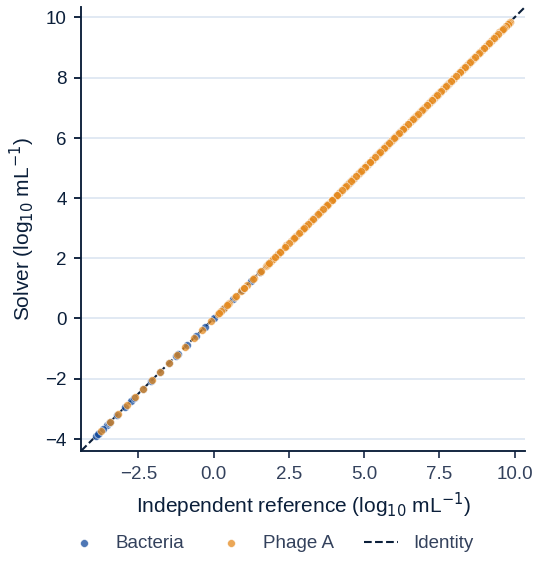

Figure 4: Solver agrees with an independent reference implementation


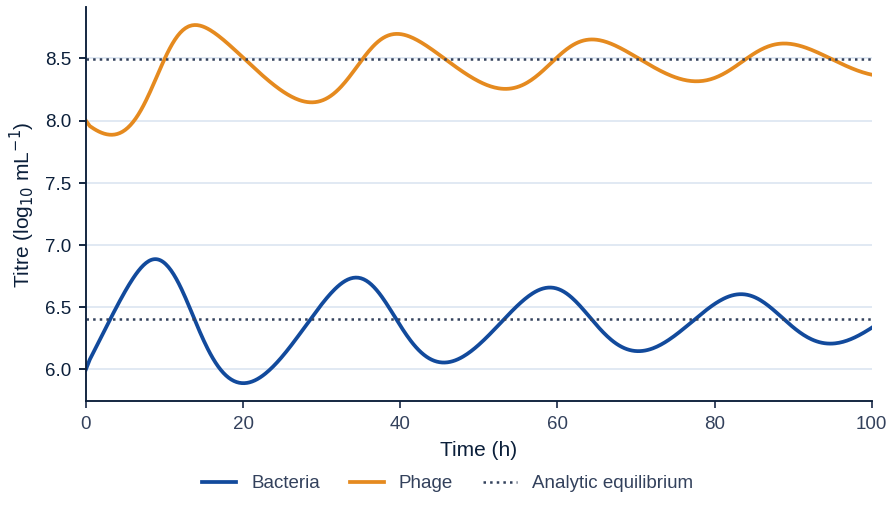

Figure 6: Chemostat dynamics at 25 ug/mL nutrient


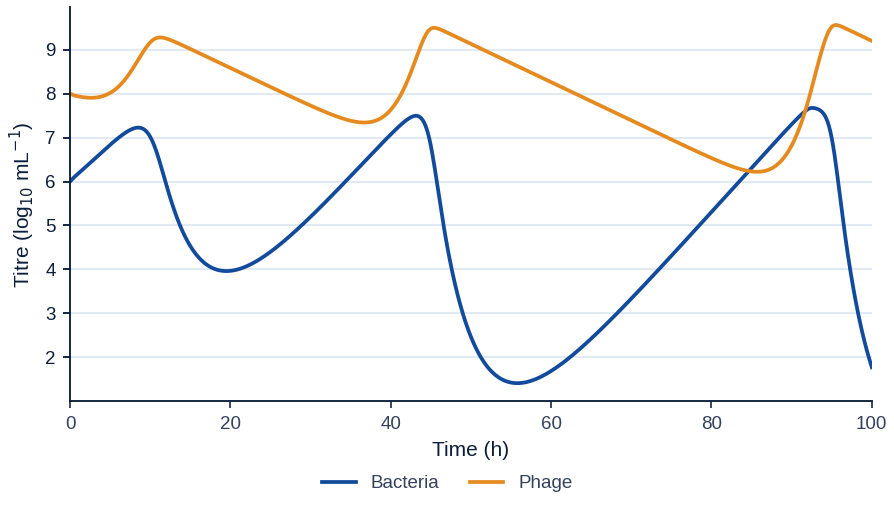

Figure 7: Chemostat dynamics at 100 ug/mL nutrient


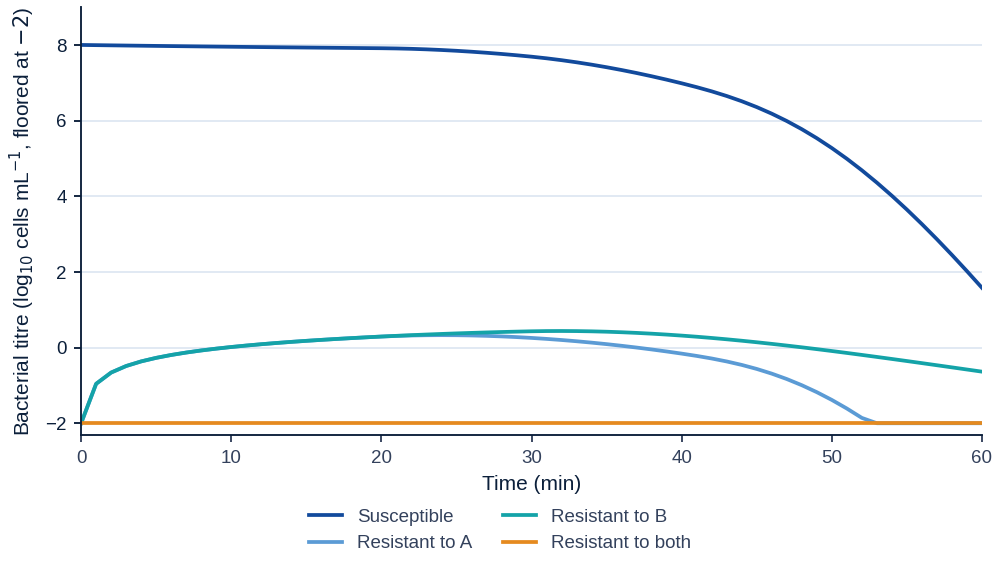

Figure 8: Bacterial subpopulations under a two-phage cocktail
Table 2: Solver validation summary


,Check,Criterion,Observed,Status
0,Phage-free chemostat steady state,|error| < 0.01 log10 vs (Cin-C*)/eps,8.2975 vs 8.2960,PASS
1,Phage decay and washout,max |error| < 0.01 log10 vs exp(-(d+w)t),0.0033,PASS
2,Latent-period timing,burst at L + one step for every step size,dt=1: burst at 36 min; dt=0.5: burst at 35.5 min; dt=0.25: burst at 35.25 min,PASS
3,Burst size,"titre at burst = burst x infected cells, within 0.02 log10",all three step sizes,PASS
4,Independent reference solver,"max |difference| < 0.005 log10 (8 random draws, 48 h)",6.22e-14,PASS
5,Finite states on random draws,"all outputs finite (64 draws, 3 step sizes)",True,PASS
6,Outcome-label agreement,>= 0.95 between 1 min and 0.25 min,1.000 (0.5 vs 0.25 min: 1.000),PASS
7,Step-size convergence,p95 |1 min vs 0.25 min| < 0.05 log10,p95 = 0.0363; p95(0.5 vs 0.25) = 0.0116,PASS
8,Lenski Fig. 2a: coexistence level,|mean of last 25 h - analytic equilibrium| < 0.15 log10,bacteria 6.39 vs 6.41; phage 8.47 vs 8.49,PASS
9,Lenski Fig. 2a: damped oscillation,amplitude(75-100 h) < amplitude(25-50 h),0.40 < 0.68,PASS


INTERNAL VALIDATION: passed (NOTE rows are informational)


In [ ]:
#solver validation
BASE_THETA = dict(log10_bacteria0=6., growth_s_per_h=.9, log10_adsorption_a=-12., log10_adsorption_b=-12.,
    latent_a_min=35., latent_b_min=35., burst_a=100., burst_b=100., log10_mutation_a=-7.,
    log10_mutation_b=-7., flow_per_h=.2, phage_decay_a_per_h=0., phage_decay_b_per_h=0.,
    log10_titre_a=-20., log10_titre_b=-20.)
def theta_from(**kw):
    d = {**BASE_THETA, **kw}
    return torch.tensor([[d[k] for k in PARAMETERS]], dtype=torch.float64)
PHYS_BASE = dict(ks=4., c_in=100., c0=None, eps=5e-7, resistant_init=(0., 0., 0.),
                 mutation=False, superinfection=False)
def phys(**kw): return {**PHYS_BASE, **kw}
LOG10E = math.log10(math.e)
CHECKS = []
def add_check(name, criterion, observed, passed, status=None):
    CHECKS.append({"Check": name, "Criterion": criterion, "Observed": observed,
                   "Status": status or ("PASS" if passed else "FAIL")})
def style_axis(ax, xlabel, ylabel):
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.grid(axis="y", zorder=0)
def legend_below(fig, ax, ncol=None):
    """Legend placed outside the axes, below the x-axis label, so it can never cover data."""
    handles, labels = ax.get_legend_handles_labels()
    ncol = ncol or len(labels)
    try:
        fig.legend(handles, labels, loc="outside lower center", ncol=ncol,
                   handlelength=1.8, columnspacing=1.6)
    except Exception:
        ax.legend(handles, labels, loc="upper center", bbox_to_anchor=(.5, -.22), ncol=ncol)
LAB_B = r"Bacterial titre (log$_{10}$ cells mL$^{-1}$)"
LAB_P = r"Phage titre (log$_{10}$ PFU mL$^{-1}$)"

# ---- V1. Phage-free chemostat: analytic steady state (burst 0 switches phages off) -----
w, mu, ks, cin, eps = .2, .9, 4., 100., 5e-7
c_star = ks*w/(mu - w); s_star = (cin - c_star)/eps
o1 = core.simulate(theta_from(flow_per_h=w, growth_s_per_h=mu, burst_a=0., burst_b=0.), list(range(0, 300*60 + 1, 300)),
                   dtype=torch.float64, phys=phys(ks=ks, c_in=cin, eps=eps))[0, :, 0].numpy()
add_check("Phage-free chemostat steady state", "|error| < 0.01 log10 vs (Cin-C*)/eps",
          f"{o1[-1]:.4f} vs {math.log10(s_star):.4f}", abs(o1[-1] - math.log10(s_star)) < .01)

# ---- V2. Phage decay and washout ------------------------------------------------------
d_a = .1
mins = list(range(0, 601, 60))
o2 = core.simulate(theta_from(log10_bacteria0=-20., log10_titre_a=8., phage_decay_a_per_h=d_a, flow_per_h=w),
                   mins, dtype=torch.float64, phys=phys())[0, :, 1].numpy()
exp2 = 8 - (d_a + w)*(np.array(mins)/60)*LOG10E
add_check("Phage decay and washout", "max |error| < 0.01 log10 vs exp(-(d+w)t)",
          f"{np.abs(o2 - exp2).max():.4f}", np.abs(o2 - exp2).max() < .01)

# ---- V3. Latent-period timing and burst size ------------------------------------------
t_ok, size_ok, rows3 = True, True, []
for dt in (1., .5, .25):
    mins = np.arange(0, 60 + 1e-9, dt)
    o3, s3 = core.simulate(theta_from(log10_adsorption_a=-4., log10_titre_a=8., latent_a_min=35.,
                           burst_a=100., burst_b=0., flow_per_h=0., growth_s_per_h=.2), mins, dt_min=dt,
                           dtype=torch.float64, phys=phys(), return_states=True)
    o3, s3 = o3[0, :, 1].numpy(), s3[0].numpy()
    k = 1 + int(np.argmax(o3[1:] > 6))
    t_ok &= abs(mins[k] - (35. + dt)) < 1e-9
    size_ok &= abs(o3[k] - (math.log10(100.) + s3[k - 1, 4])) < .02
    rows3.append(f"dt={dt:g}: burst at {mins[k]:g} min")
add_check("Latent-period timing", "burst at L + one step for every step size", "; ".join(rows3), t_ok)
add_check("Burst size", "titre at burst = burst x infected cells, within 0.02 log10", "all three step sizes", size_ok)

# ---- V4. Independent numpy reference (single phage, written separately) ---------------
def reference(th, minutes, dt_min=1., ks=5., c_in=100., eps=2e-6):
    b0, mu_, lat, burst, flow_, dec, p0, ad = (th['log10_bacteria0'], th['growth_s_per_h'], th['latent_a_min'],
        th['burst_a'], th['flow_per_h'], th['phage_decay_a_per_h'], th['log10_titre_a'], 10.**th['log10_adsorption_a'])
    dt_h = dt_min/60.; qlen = int(60/dt_min); L = int(np.clip(np.round(lat), 10, 60)/dt_min)
    S, P, C = 10.**b0, 10.**p0, c_in; I = np.zeros(qlen); head = 0
    steps = np.rint(np.asarray(minutes)/dt_min).astype(int); out = []
    rec = lambda: out.append([np.log10(max(S + I.sum(), 1e-30)), np.log10(max(P, 1e-30))])
    rec(); cur = 1
    for s in range(steps[-1]):
        C += dt_h*flow_*(c_in - C)
        new = S*mu_*(C/(C + ks))*dt_h
        S = S + new - S*flow_*dt_h; C = max(C - eps*new, 0.)
        I *= max(1. - flow_*dt_h, 0.)
        due = I[head]; I[head] = 0.
        P += burst*due; P *= max(1. - (dec + flow_)*dt_h, 0.)
        head = (head + 1) % qlen
        bound = min(ad*S*P*dt_min, P); hit = min(bound, S)
        P -= bound; S -= hit; I[(head + L - 1) % qlen] += hit
        if cur < len(steps) and s + 1 == steps[cur]:
            rec(); cur += 1
    return np.array(out)

g = torch.Generator().manual_seed(SEED + 41)
unit = torch.rand(8, 15, generator=g).double()
bnd = torch.tensor(BOUNDS, dtype=torch.float64)
theta_r = bnd[:, 0] + unit*(bnd[:, 1] - bnd[:, 0])
theta_r[:, 14] = -20.
theta_r[:, 7] = 0.   # phage B non-productive (burst 0), so the single-phage reference is exact
mins = list(range(0, 48*60 + 1, 60))
sim_r = core.simulate(theta_r, mins, dtype=torch.float64,
                      phys=dict(resistant_init=(0., 0., 0.), mutation=False, superinfection=False)).numpy()
ref_r = np.stack([reference(dict(zip(PARAMETERS, theta_r[i].tolist())), mins) for i in range(8)])
xs, ys, kinds = [], [], []
for ch, name in ((0, "Bacteria"), (1, "Phage A")):
    a, b = ref_r[:, :, ch].ravel(), sim_r[:, :, ch].ravel()
    keep = (a > -8) & (b > -8)
    xs.append(a[keep]); ys.append(b[keep]); kinds.append(name)
dev4 = max(np.abs(x - y).max() for x, y in zip(xs, ys))
add_check("Independent reference solver", "max |difference| < 0.005 log10 (8 random draws, 48 h)",
          f"{dev4:.2e}", dev4 < .005)
fig, ax = new_figure(FIG_W1*1.3, 3.8)
for x, y, k, c in zip(xs, ys, kinds, (BLUE["deep"], ACCENT["amber"])):
    ax.scatter(x, y, s=14, color=c, alpha=.75, edgecolor="white", linewidth=.3, label=k, zorder=3)
lim = [min(map(np.min, xs)) - .5, max(map(np.max, xs)) + .5]
ax.plot(lim, lim, color=BLUE["ink"], lw=1, ls="--", zorder=2, label="Identity"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_aspect("equal", adjustable="box")
style_axis(ax, r"Independent reference (log$_{10}$ mL$^{-1}$)", r"Solver (log$_{10}$ mL$^{-1}$)")
legend_below(fig, ax)
save_figure(fig, 4, "Solver agrees with an independent reference implementation")

# ---- V5. Random-draw robustness, step-size convergence, label agreement ---------------
unit = torch.rand(64, 15, generator=g).double()
theta_c = (bnd[:, 0] + unit*(bnd[:, 1] - bnd[:, 0])).float()
mins = CFG["full_minutes"]
runs = {dt: core.simulate(theta_c, mins, dt_min=dt, return_states=True) for dt in (1., .5, .25)}
finite = all(torch.isfinite(o).all() and torch.isfinite(s).all() for o, s in runs.values())
add_check("Finite states on random draws", "all outputs finite (64 draws, 3 step sizes)", str(bool(finite)), bool(finite))
lab = {dt: core.outcomes(runs[dt][0], mins) for dt in runs}
agree1 = (lab[1.] == lab[.25]).float().mean().item()
agree5 = (lab[.5] == lab[.25]).float().mean().item()
add_check("Outcome-label agreement", ">= 0.95 between 1 min and 0.25 min",
          f"{agree1:.3f} (0.5 vs 0.25 min: {agree5:.3f})", agree1 >= .95)
d1 = (runs[1.][0] - runs[.25][0]).abs().flatten().numpy()
d2 = (runs[.5][0] - runs[.25][0]).abs().flatten().numpy()
add_check("Step-size convergence", "p95 |1 min vs 0.25 min| < 0.05 log10",
          f"p95 = {np.quantile(d1, .95):.4f}; p95(0.5 vs 0.25) = {np.quantile(d2, .95):.4f}", np.quantile(d1, .95) < .05)

# ---- V6. Reproduction of the paper's shipped examples (parameters read from the .ctl files) ----
from scipy.optimize import brentq
LEN = dict(mu=.7, ks=5., eps=2e-6, flow=.2, ad=1.67e-11, lat=30., burst=100., b0=6., p0=8.)   # Lenski_1988_Fig_2a/2b.ctl
def run_lenski(c):
    th = theta_from(log10_bacteria0=LEN['b0'], growth_s_per_h=LEN['mu'], log10_adsorption_a=math.log10(LEN['ad']),
                    latent_a_min=LEN['lat'], burst_a=LEN['burst'], burst_b=0., flow_per_h=LEN['flow'],
                    phage_decay_a_per_h=0., phage_decay_b_per_h=0., log10_titre_a=LEN['p0'], log10_titre_b=-20.)
    mins = list(range(0, 100*60 + 1, 10))
    o = core.simulate(th, mins, dtype=torch.float64,
        phys=phys(ks=LEN['ks'], eps=LEN['eps'], c_in=c, c0=c, growth_ratio=(1., 1., 1., 1.)))[0].numpy()
    return np.array(mins)/60, o
def equilibrium(c):
    w_, d, b, L = LEN['flow'], LEN['ad']*60, LEN['burst'], LEN['lat']/60
    s = w_/(d*(b*math.exp(-w_*L) - 1))
    mu_ = lambda C: LEN['mu']*C/(LEN['ks'] + C)
    C = brentq(lambda C: w_*(c - C) - LEN['eps']*mu_(C)*s, 0., c)
    p = (mu_(C) - w_)/d
    return math.log10(s*(1 + d*p*(1 - math.exp(-w_*L))/w_)), math.log10(p)

t, o25 = run_lenski(25.); _, o100 = run_lenski(100.); n_eq, p_eq = equilibrium(25.)
tail, mid = t > 75, (t > 25) & (t <= 50)
mb, mp = o25[tail, 0].mean(), o25[tail, 1].mean()
add_check("Lenski Fig. 2a: coexistence level", "|mean of last 25 h - analytic equilibrium| < 0.15 log10",
          f"bacteria {mb:.2f} vs {n_eq:.2f}; phage {mp:.2f} vs {p_eq:.2f}", abs(mb - n_eq) < .15 and abs(mp - p_eq) < .15)
add_check("Lenski Fig. 2a: damped oscillation", "amplitude(75-100 h) < amplitude(25-50 h)",
          f"{np.ptp(o25[tail, 0]):.2f} < {np.ptp(o25[mid, 0]):.2f}", np.ptp(o25[tail, 0]) < np.ptp(o25[mid, 0]))
add_check("Lenski Fig. 2b: large oscillations, no extinction", "amplitude(100) > 3 x amplitude(25); 0 < min log10 titre < 3",
          f"{np.ptp(o100[tail, 0]):.2f} vs {np.ptp(o25[tail, 0]):.2f}; min {o100[:, 0].min():.2f}",
          np.ptp(o100[tail, 0]) > 3*np.ptp(o25[tail, 0]) and 0 < o100[:, 0].min() < 3)
add_check("Note: paper text vs shipped .ctl", "paper text says bacteria ~1e7, phage ~1e9 (rounded)",
          f"equilibrium implied by the .ctl: {n_eq:.2f}, {p_eq:.2f} (log10)", True, status="NOTE")
for o, num, nm in ((o25, 6, "Chemostat dynamics at 25 ug/mL nutrient"), (o100, 7, "Chemostat dynamics at 100 ug/mL nutrient")):
    fig, ax = new_figure(FIG_W1*1.7, 3.4)
    ax.plot(t, o[:, 0], color=PALETTE["bacteria"], label="Bacteria")
    ax.plot(t, o[:, 1], color=PALETTE["phage_a"], label="Phage")
    if num == 6:
        ax.axhline(n_eq, color=BLUE["text"], ls=":", lw=1.2, label="Analytic equilibrium")
        ax.axhline(p_eq, color=BLUE["text"], ls=":", lw=1.2)
    ax.set_xlim(0, 100)
    style_axis(ax, "Time (h)", r"Titre (log$_{10}$ mL$^{-1}$)"); legend_below(fig, ax)
    save_figure(fig, num, nm)

# Fig_2D.ctl: two phages, B has the shorter latent period; Standard infection, Uninfected adsorption, deterministic mutation
th = theta_from(log10_bacteria0=8., growth_s_per_h=.7, log10_adsorption_a=-10., log10_adsorption_b=-10.,
                latent_a_min=30., latent_b_min=20., burst_a=100., burst_b=100., log10_mutation_a=-7., log10_mutation_b=-7.,
                flow_per_h=.2, phage_decay_a_per_h=0., phage_decay_b_per_h=0., log10_titre_a=8., log10_titre_b=8.)
pp = phys(ks=5., eps=2e-6, c_in=100., c0=100., growth_ratio=(1., 1., 1., 1.), mutation=True, superinfection=True)
o1h, s1h = core.simulate(th, list(range(0, 61)), dt_min=.25, dtype=torch.float64, return_states=True, phys=pp)
o48, s48 = core.simulate(th, list(range(0, 48*60 + 1, 60)), dt_min=1., dtype=torch.float64, return_states=True, phys=pp)
o1h, s1h, o48, s48 = o1h[0].numpy(), s1h[0].numpy(), o48[0].numpy(), s48[0].numpy()
add_check("Fig. 2D: shorter-latency phage B outcompetes A", "titre_B > titre_A after 1 h",
          f"B {o1h[-1, 2]:.2f} vs A {o1h[-1, 1]:.2f}", o1h[-1, 2] > o1h[-1, 1])
add_check("Fig. 2D: double-resistant cells after 48 h", "paper: about 1e3 cells/mL; accept 2-4 log10 (rounded statement)",
          f"{s48[-1, 3]:.2f}", 2. <= s48[-1, 3] <= 4.)
add_check("Note: Fig. 2D A-resistant cells", "paper: disappear within an hour",
          f"peak {s1h[:, 1].max():.2f}, at 1 h {s1h[-1, 1]:.2f} (log10 cells/mL)", True, status="NOTE")
fig, ax = new_figure(FIG_W1*1.9, 3.8)
for j, (nm, c) in enumerate((("Susceptible", BLUE["deep"]), ("Resistant to A", BLUE["sky"]),
                             ("Resistant to B", ACCENT["teal"]), ("Resistant to both", ACCENT["amber"]))):
    ax.plot(np.arange(61), np.maximum(s1h[:, j], -2), color=c, label=nm)
ax.set_xlim(0, 60); ax.set_ylim(-2.3, 9)
style_axis(ax, "Time (min)", r"Bacterial titre (log$_{10}$ cells mL$^{-1}$, floored at $-2$)")
legend_below(fig, ax, ncol=2)
save_figure(fig, 8, "Bacterial subpopulations under a two-phage cocktail")

# ---- summary table (the result of this whole section) ----
VALIDATION = pd.DataFrame(CHECKS)
pd.set_option("display.max_colwidth", None)
save_table(VALIDATION, 2, "Solver validation summary")
print("INTERNAL VALIDATION:", "FAILED - do not proceed" if (VALIDATION["Status"] == "FAIL").any()
      else "passed (NOTE rows are informational)")

## Cell 4: Independent sharded development cohorts

This cell generates the seven development cohorts (training, robust training, validation, temperature calibration, OOD calibration, policy tuning and policy lockbox). The certification and stress cohorts are **not** generated here. They are generated in a later cell, only after the solver is frozen and the policy has passed the lockbox.

**How a cohort is generated**

- Each cohort is split into shards of 512 cases. Shard *s* of a cohort with seed σ is seeded with 10⁴σ + *s*, and assay noise is seeded separately with that value plus 5 × 10⁸, so no parameter vector or noise realisation is shared between cohorts.
- For each shard, the 15 parameters are drawn uniformly from the prior bounds, the solver simulates 24 h trajectories every 15 min, and the sparse assay model is applied at the master times (0, 15, 30, 60, 90, 120, 180, 240 and 360 min).
- The training and robust-training cohorts receive bounded assay augmentation (35% and 65% of cases, respectively). All other development cohorts use the reference assay conditions.
- Every shard stores the parameters, the full and clean trajectories, the observations (values, missingness, censoring, detection limit), the outcome label and the 24 h endpoint. It also stores the run fingerprint and solver digest.
- Cohort generation runs on CPU in single precision, because 512-case shards are launch-bound on a GPU. Deterministic-algorithm checking is switched off for this step because generation is fully seeded.

**Data integrity**

- Each shard is written atomically and listed in a per-cohort `manifest.csv` with its SHA-256 digest.
- Existing shards are reused (so an interrupted run can resume) only if their run fingerprint and index range match. Loading a cohort re-verifies every digest and the continuity of the shard ranges.
- All cohort seeds must be unique (asserted).
- Training shards produced by a different solver or configuration are removed automatically. For the other cohorts, a fingerprint mismatch stops the run with an assertion error, so use a new output directory after any change.

**Outputs.** Shards and manifests under `data/<cohort>/`, and `tables/development_outcomes.csv` (outcome counts per cohort). Outcome prevalences are stable across the development cohorts, at roughly 23% sustained clearance, 13% rebound, 29–30% partial control and 34–35% failure or persistence.

**Note.** Generating the 90,000 training and robust-training cases takes about 10 min on CPU in the reported run. The shard files are large and are not needed to reproduce the results, because they can be regenerated from the code and seeds.

In [ ]:
import shutil
_stale = ROOT/"data"/"train"
_first = sorted(_stale.glob("shard_*.pt"))[:1]
if _first and torch.load(_first[0], map_location="cpu", weights_only=True)["run_id"] != RUN_ID:
    shutil.rmtree(_stale)   # remove only training shards produced by a different solver or configuration
# independent sharded cohorts
SIM_DEVICE = torch.device("cpu")
torch.use_deterministic_algorithms(False)

def generate_cohort(spec):
    folder = ROOT/'data'/spec['name']; folder.mkdir(parents=True, exist_ok=True)
    n, size = spec['n'], CFG['shard_size']; scenario = spec['scenario']; bounds = torch.tensor(CFG['bounds'])
    master_idx = torch.searchsorted(torch.tensor(CFG['full_minutes']), torch.tensor(CFG['master_minutes']))
    assert torch.equal(torch.tensor(CFG['full_minutes'])[master_idx], torch.tensor(CFG['master_minutes']))
    rows = []; began = time.perf_counter(); n_shards = math.ceil(n/size); generated = 0
    for shard_id, start in enumerate(range(0, n, size)):
        stop = min(start + size, n); path = folder/f'shard_{start:06d}_{stop:06d}.pt'
        if path.exists():
            shard = torch.load(path, map_location='cpu', weights_only=True)
            assert shard['run_id'] == RUN_ID
            assert shard['start'] == start and shard['stop'] == stop
            status = 'reused'
        else:
            seed = spec['seed']*10000 + shard_id
            generator = torch.Generator().manual_seed(seed)
            unit = torch.rand(stop - start, 15, generator=generator)
            if scenario.get('kinetic_shift', False):
                unit[:, 1] = .5 + .5*unit[:, 1]; unit[:, 2:4] *= .5
            if scenario.get('low_titre', False): unit[:, 13:15] *= .5
            theta = bounds[:, 0] + unit*(bounds[:, 1] - bounds[:, 0])
            full = core.simulate(theta, CFG['full_minutes'], SIM_DEVICE).cpu(); clean = full[:, master_idx]
            obs_cfg = CFG if spec['name'] != 'robust_train' else {**CFG, 'training_augmentation_fraction': CFG['robust_training_augmentation_fraction']}
            obs = core.observe(clean, obs_cfg, seed + 500000000, scenario=scenario,
                               augmented=(spec['name'] in ('train', 'robust_train')))
            shard = {'run_id': RUN_ID, 'core_sha256': CORE_SHA, 'start': start, 'stop': stop,
                     'theta_unit': unit, 'theta_physical': theta, 'full_values': full, 'clean_master': clean,
                     'label': core.outcomes(full, CFG['full_minutes']), 'endpoint': full[:, -1, 0], **obs}
            for key in ('full_values', 'values', 'theta_physical'):
                assert torch.isfinite(shard[key]).all(), key
            save_pt(path, shard); status = 'generated'; generated += 1
        rows.append({'cohort': spec['name'], 'start': start, 'stop': stop, 'n': stop - start,
                     'file': path.name, 'sha256': sha256(path), 'status': status})
        if shard_id % 10 == 0 or stop == n:
            el = time.perf_counter() - began
            eta = el/max(generated, 1)*(n_shards - shard_id - 1) if generated else 0.
            print(f"{spec['name']:<16} {stop:>6}/{n}  elapsed {el:6.1f}s  eta {eta:6.1f}s  {status}", flush=True)
    manifest = pd.DataFrame(rows); manifest.to_csv(folder/'manifest.csv', index=False)
    return manifest

def load_cohort(name):
    folder = ROOT/'data'/name
    manifest = pd.read_csv(folder/'manifest.csv').sort_values('start')
    assert manifest.iloc[0]['start'] == 0
    assert np.array_equal(manifest['start'].to_numpy()[1:], manifest['stop'].to_numpy()[:-1])
    keys = ['theta_unit', 'theta_physical', 'full_values', 'clean_master', 'label', 'endpoint',
            'values', 'observed', 'censored', 'lod']; parts = {key: [] for key in keys}
    for row in manifest.itertuples(index=False):
        path = folder/row.file; assert sha256(path) == row.sha256
        shard = torch.load(path, map_location='cpu', weights_only=True); assert shard['run_id'] == RUN_ID
        for key in keys: parts[key].append(shard[key])
    return {key: torch.cat(value) for key, value in parts.items()}

assert len({c['seed'] for c in COHORT_PLAN}) == len(COHORT_PLAN), 'cohort seeds must be unique'
DEVELOPMENT = [x for x in COHORT_PLAN if x['name'] in
               ('train', 'robust_train', 'validation', 'temperature', 'ood_calibration', 'policy_tuning', 'policy_lockbox')]
print('Solver settings:', core.PHYS_DEFAULT, '| simulation device:', SIM_DEVICE, flush=True)
for spec in DEVELOPMENT: generate_cohort(spec)
DATA = {spec['name']: load_cohort(spec['name']) for spec in DEVELOPMENT}
counts = []
for name, data in DATA.items():
    for cls, label in enumerate(CFG['outcomes']):
        counts.append({'cohort': name, 'outcome': label, 'count': int((data['label'] == cls).sum())})
pd.DataFrame(counts).to_csv(ROOT/'tables'/'development_outcomes.csv', index=False)
display(pd.DataFrame(counts))

Solver settings: {'ks': 5.0, 'c_in': 100.0, 'c0': None, 'eps': 2e-06, 'resistant_init': (1e-07, 1e-07, 1e-14), 'growth_ratio': (1.0, 0.9, 0.9, 0.8), 'mutation': True, 'superinfection': True} | simulation device: cpu
train               512/60000  elapsed    3.4s  eta  396.3s  generated
train              5632/60000  elapsed   37.1s  eta  361.0s  generated
train             10752/60000  elapsed   70.5s  eta  325.7s  generated
train             15872/60000  elapsed  103.7s  eta  291.1s  generated
train             20992/60000  elapsed  137.2s  eta  257.6s  generated
train             26112/60000  elapsed  170.6s  eta  224.1s  generated
train             31232/60000  elapsed  203.8s  eta  190.4s  generated
train             36352/60000  elapsed  237.2s  eta  157.0s  generated
train             41472/60000  elapsed  270.1s  eta  123.4s  generated
train             46592/60000  elapsed  302.9s  eta   89.9s  generated
train             51712/60000  elapsed  335.7s  eta   56.5s  generated
tra

,cohort,outcome,count
0,train,sustained_clearance,13774
1,train,rebound,7795
2,train,partial_control,17689
3,train,failure_or_persistence,20742
4,robust_train,sustained_clearance,6910
5,robust_train,rebound,3912
6,robust_train,partial_control,8970
7,robust_train,failure_or_persistence,10208
8,validation,sustained_clearance,2235
9,validation,rebound,1311


## Cell 5: Cohort results — outcome prevalence and median trajectories

This cell summarises the development cohorts generated in cell 4. It confirms that the four outcome classes are well populated and similar across cohorts, and shows how the classes separate over the first hours.

- **Table 3** reports the share of each outcome (sustained clearance, rebound, partial control, failure or persistence) in every development cohort. Similar prevalences across cohorts show that the cohorts are comparable draws from the same prior.
- **Figure 9** shows the median total bacterial trajectory of each outcome class in the training cohort, with the interquartile range shaded. Values are floored at 10⁻² cells mL⁻¹, the detection floor shown on the axis.

**How to read Figure 9.** Sustained clearance reaches the detection floor after about 2 h. Rebound passes through a nadir near 3 h and then regrows. Partial control stays low (about 10¹ cells mL⁻¹ at 4–6 h), and failure or persistence stays high throughout. Between 2 and 4 h, the medians for sustained clearance and rebound differ by less than two log₁₀ units, whereas failure or persistence stays more than three log₁₀ units higher. This is why failure can be called early (2 h) while rebound calls are deferred to later stages.

**Outputs.** `Table_03_Outcome_prevalence_by_development_cohort.csv` and `.tex`, and `Figure_09_Median_bacterial_trajectories_by_outcome_class.pdf` and `.png`.

**Note.** These are noise-free simulated trajectories (`full_values`), used only to illustrate the outcome definitions. The models never see them. They see the sparse, noisy, censored observations at 2, 4 and 6 h.

Table 3: Outcome prevalence by development cohort


,Cohort,Trajectories,Sustained clearance (%),Rebound (%),Partial control (%),Failure or persistence (%)
0,Training,60000,23.0,13.0,29.5,34.6
1,Robust training,30000,23.0,13.0,29.9,34.0
2,Validation,10000,22.4,13.1,29.9,34.6
3,Temperature calibration,10000,22.5,13.2,29.2,35.0
4,OOD calibration,10000,22.6,12.9,29.4,35.0
5,Policy tuning,30000,23.0,13.0,29.4,34.7
6,Policy lockbox,30000,22.8,13.1,29.4,34.6


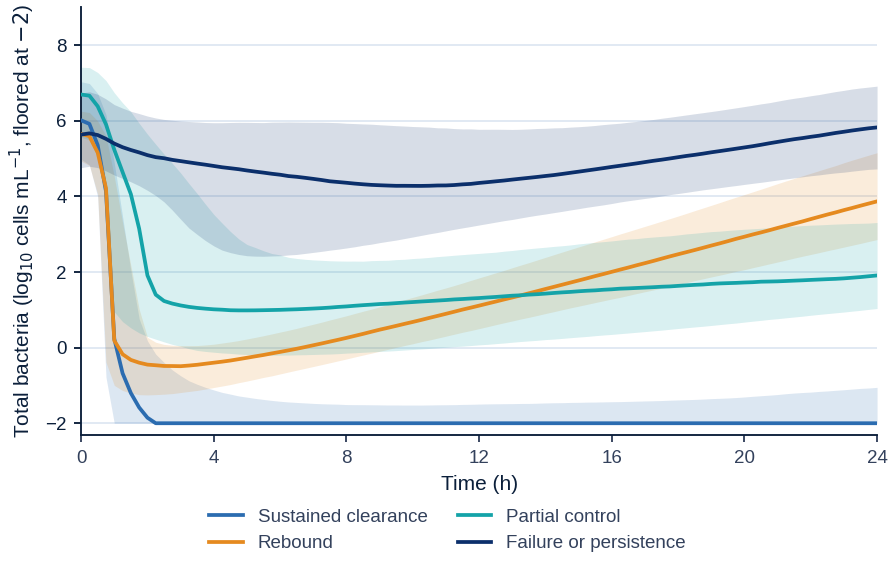

Figure 9: Median bacterial trajectories by outcome class


In [ ]:
#Cohort results
OUT_NAMES = ["Sustained clearance", "Rebound", "Partial control", "Failure or persistence"]
OUT_COLOR = [BLUE["mid"], ACCENT["amber"], ACCENT["teal"], BLUE["navy"]]
rows = []
for name in DATA:
    lab = DATA[name]["label"]; frac = torch.bincount(lab, minlength=4).float()/len(lab)*100
    rows.append({"Cohort": PRETTY[name], "Trajectories": len(lab),
                 **{o + " (%)": round(float(f), 1) for o, f in zip(OUT_NAMES, frac)}})
save_table(pd.DataFrame(rows), 3, "Outcome prevalence by development cohort")

tr = DATA["train"]; hours = np.array(CFG["full_minutes"])/60.
fig, ax = new_figure(FIG_W1*1.7, 3.8)
for k, (o, c) in enumerate(zip(OUT_NAMES, OUT_COLOR)):
    b = tr["full_values"][tr["label"] == k][:, :, 0].numpy()
    q25, q50, q75 = np.quantile(b, [.25, .5, .75], axis=0)
    ax.fill_between(hours, np.maximum(q25, -2), np.maximum(q75, -2), color=c, alpha=.16, linewidth=0, zorder=2)
    ax.plot(hours, np.maximum(q50, -2), color=c, label=o, zorder=3)
ax.set_xlim(0, 24); ax.set_ylim(-2.3, 9); ax.set_xticks(range(0, 25, 4))
ax.set_xlabel("Time (h)"); ax.set_ylabel(r"Total bacteria (log$_{10}$ cells mL$^{-1}$, floored at $-2$)")
ax.grid(axis="y", zorder=0)
legend_below(fig, ax, ncol=2)
save_figure(fig, 9, "Median bacterial trajectories by outcome class")

## Cell 6: Training-only normalisation, input features and assay schedule

This cell converts the observed assay data into the network inputs. All normalisation constants are estimated on the training cohort only, so no information from the validation, calibration, tuning, lockbox or certification cohorts enters preprocessing.

**Normalisation**

- For each decision stage (2, 4 and 6 h) and each channel (total bacteria, phage A, phage B), the mean and standard deviation are computed from the training-cohort entries that were both measured and available at that decision time. The standard deviation is bounded below by 10⁻³. Censored values enter at the detection limit.
- The 24 h endpoint is standardised with the training-cohort mean and standard deviation.
- The same constants are then applied unchanged to every other cohort.

**Input representation.** Each case at each stage is a sequence of nine tokens, one per scheduled measurement time (0, 15, 30, 60, 90, 120, 180, 240 and 360 min). Each token has 19 features: the standardised value, a measured indicator and a censored indicator for each of the three channels, the standardised detection limit, the scaled time, the change from the previous time point, and the pairwise differences between channels. Values not yet available at the decision time are set to zero, with their indicators set to zero. The code checks that every feature array has 19 features and contains no non-finite values.

**Assay schedule (Figure 10).** Total bacterial concentration is available at every scheduled time up to the decision time, giving 6, 8 and 9 bacterial measurements at the 2, 4 and 6 h stages. Phage titres are available only at 0, 120 and 360 min, giving two values (0 and 2 h) at the first two stages and three (0, 2 and 6 h) at the 6 h stage. The schedule therefore supplies more bacterial than phage information.

**Outputs.** `models/preprocessing.pt` (normalisation constants, endpoint constants and run fingerprint) and Figure 10 (sparse assay schedule by decision stage). In the figure, filled symbols mark measurements available at the decision time and open symbols mark those not yet available.

**Note.** Time enters the network only through the scaled time feature. The network has no positional encoding.

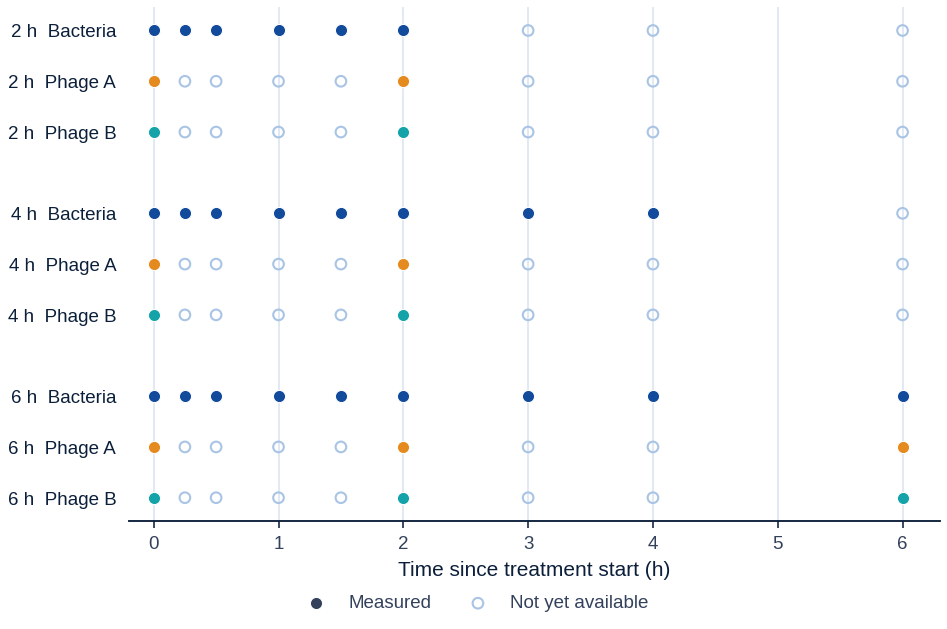

Figure 10: Sparse assay schedule by decision stage


In [ ]:
#training-only normalisation and features
STATS = {}
for stage, hour in enumerate(CFG['hours']):
    available = core.schedule_mask(CFG['master_minutes'], hour)[None]
    seen = DATA['train']['observed'] & available; mean = []; std = []
    for c in range(3):
        values = DATA['train']['values'][:, :, c][seen[:, :, c]]
        mean.append(values.mean()); std.append(values.std().clamp_min(1e-3))
    STATS[stage] = {'mean': torch.stack(mean), 'std': torch.stack(std)}
END_MEAN = DATA['train']['endpoint'].mean(); END_STD = DATA['train']['endpoint'].std().clamp_min(1e-3)
FEATURES = {name: [core.features(data, CFG, hour, STATS[k]['mean'], STATS[k]['std'])
            for k, hour in enumerate(CFG['hours'])] for name, data in DATA.items()}
for name, feats in FEATURES.items():
    for k, f in enumerate(feats):
        assert f.shape[-1] == CFG['feature_dims'][k] and torch.isfinite(f).all(), (name, k)
save_pt(ROOT/'models'/'preprocessing.pt', dict(run_id=RUN_ID, stats=STATS, endpoint_mean=END_MEAN, endpoint_std=END_STD))

# ---- result of this step: the sparse assay design ----
CH = ["Bacteria", "Phage A", "Phage B"]
times = np.array(CFG['master_minutes'])/60.
CH_COLOR = [BLUE["deep"], ACCENT["amber"], ACCENT["teal"]]
fig, ax = new_figure(FIG_W1*1.8, 4.2)
ypos, ylabels, y = [], [], 0.0
for k, h in enumerate(CFG['hours']):
    mask = core.schedule_mask(CFG['master_minutes'], h).numpy()
    for c in range(3):
        ax.scatter(times[~mask[:, c]], np.full((~mask[:, c]).sum(), y), s=26, facecolor="none",
                   edgecolor=BLUE["pale"], linewidth=1.0, zorder=2)
        ax.scatter(times[mask[:, c]], np.full(mask[:, c].sum(), y), s=34, color=CH_COLOR[c],
                   edgecolor="white", linewidth=.5, zorder=3)
        ylabels.append(f"{h:g} h  {CH[c]}"); ypos.append(y); y += 1.0
    y += .6
ax.set_yticks(ypos); ax.set_yticklabels(ylabels); ax.invert_yaxis()
ax.tick_params(axis="y", length=0, pad=6); ax.spines["left"].set_visible(False)
ax.set_xlabel("Time since treatment start (h)"); ax.set_xlim(-.2, 6.3); ax.set_xticks(range(0, 7))
ax.grid(axis="x", zorder=0)
ax.scatter([], [], s=34, color=BLUE["text"], edgecolor="white", linewidth=.5, label="Measured")
ax.scatter([], [], s=26, facecolor="none", edgecolor=BLUE["pale"], linewidth=1.0, label="Not yet available")
legend_below(fig, ax, ncol=2)
save_figure(fig, 10, "Sparse assay schedule by decision stage")

## Cell 7: Three-member Transformer ensembles for each decision stage

This cell trains one deep ensemble for each decision stage (2, 4 and 6 h). Each ensemble has three Transformer members that differ only in their random initialisation and mini-batch order, giving nine networks in total.

**What each network predicts.** Each Transformer has three heads on a shared representation: a four-class outcome classifier, a five-component Gaussian mixture density for the standardised 24 h endpoint, and a binary action head. The action is *failure or persistence* at 2 h and *rebound* at 4 h and 6 h. The action head drives the selective policy.

**Training objective**

L = L_CE + 0.25 · L_MDN + L_BCE + 0.25 · L_rank

- `L_CE` is the multiclass cross-entropy, `L_MDN` is the negative log-likelihood of the mixture density for the endpoint, and `L_BCE` is the binary cross-entropy of the action head.
- `L_rank` is a hard-pair ranking term. It compares the lowest-scoring positives with the highest-scoring negatives in each mini-batch (at most 128 pairs) and concentrates capacity near the high-precision boundary where the policy operates. It contributes zero if either set is empty.

**Training protocol**

- Training data are the training and robust-training cohorts combined (90,000 cases). The validation cohort (10,000 cases) is used for model selection only.
- AdamW (learning rate 3 × 10⁻⁴, weight decay 10⁻⁴), mini-batches of 256, gradient-norm clipping at 1.0, and a maximum of 180 epochs.
- After each epoch the objective is evaluated on the validation cohort with dropout disabled. The best checkpoint is kept, and training stops when the validation objective has not improved by more than 10⁻⁴ for 20 epochs.
- Member *j* of stage *s* is initialised with seed 20261002 + 1000*s* + 100*j*, and the mini-batch order of epoch *e* is drawn with that seed plus *e*.
- A "last" checkpoint with optimiser state is saved every epoch, so an interrupted run resumes exactly. Checkpoints carry the run fingerprint, and a mismatch stops the run.

**Outputs.** `models/stage_<s>_member_<m>_best.pt` (selected checkpoints, used downstream), `models/stage_<s>_member_<m>_last.pt` (resume state only), per-member training curves in `tables/training_stage_<s>_member_<m>.csv`, and Table 4 (ensemble training summary: epochs run, best epoch, best validation loss and final training loss).

**Notes**
- In the reported run, all nine members stopped on the patience criterion between 95 and 124 epochs.
- Downstream, the class and endpoint outputs come from the first member of each ensemble. The action probability is the average over all three members.

In [ ]:
#three-member ensembles for every decision stage
ACTION_CLASS = {0: 3, 1: 1, 2: 1}
ENSEMBLE_SIZES = [CFG['action_ensemble_size']]*3

def objective(model, x, labels, endpoint, stage):
    logits, w, m, s, action_logit, _ = model(x)
    target = (labels == ACTION_CLASS[stage]).float()
    action_loss = F.binary_cross_entropy_with_logits(action_logit, target)
    pos = action_logit[target.bool()]; neg = action_logit[~target.bool()]
    if len(pos) and len(neg):
        pair_n = min(len(pos), len(neg), 128)
        pos_pair = pos.topk(pair_n, largest=False).values
        neg_pair = neg.topk(pair_n, largest=True).values
        ranking = F.softplus(-(pos_pair - neg_pair)).mean()
    else:
        ranking = action_logit.sum()*0.
    return (F.cross_entropy(logits, labels)
            + CFG['endpoint_loss_weight']*core.mixture_nll(w, m, s, endpoint)
            + CFG['action_loss_weight']*action_loss + CFG['ranking_loss_weight']*ranking)

@torch.no_grad()
def validation_loss(model, x, labels, endpoint, stage):
    model.eval(); total = torch.zeros((), device=x.device)
    for start in range(0, len(x), CFG['inference_batch']):
        sl = slice(start, start + CFG['inference_batch'])
        total += objective(model, x[sl], labels[sl], endpoint[sl], stage).detach()*len(x[sl])
    return float(total)/len(x)

MODELS = []; HISTORIES = []; SUMMARY = []
for stage, hour in enumerate(CFG['hours']):
    dev = DEVICE
    train_label = torch.cat((DATA['train']['label'], DATA['robust_train']['label'])).to(dev)
    train_end = ((torch.cat((DATA['train']['endpoint'], DATA['robust_train']['endpoint'])) - END_MEAN)/END_STD).to(dev)
    train_x = torch.cat((FEATURES['train'][stage], FEATURES['robust_train'][stage])).to(dev)
    val_x = FEATURES['validation'][stage].to(dev); val_label = DATA['validation']['label'].to(dev)
    val_end = ((DATA['validation']['endpoint'] - END_MEAN)/END_STD).to(dev)
    stage_models, stage_tables = [], []
    for member in range(ENSEMBLE_SIZES[stage]):
        print(f'\nTraining {hour:g} h model, member {member+1}/{ENSEMBLE_SIZES[stage]}, action {CFG["outcomes"][ACTION_CLASS[stage]]}', flush=True)
        member_seed = SEED + stage*1000 + member*100
        torch.manual_seed(member_seed)
        model = core.Model(CFG['width'], CFG['mixture_components'], CFG['feature_dims'][stage]).to(dev)
        optimizer = torch.optim.AdamW(model.parameters(), lr=CFG['learning_rate'], weight_decay=1e-4)
        stem = f'stage_{stage}_member_{member}'
        last_path = ROOT/'models'/f'{stem}_last.pt'; best_path = ROOT/'models'/f'{stem}_best.pt'
        history = []; best = float('inf'); stale = 0; first_epoch = 0
        if last_path.exists():
            ck = torch.load(last_path, map_location='cpu', weights_only=True)
            assert ck['run_id'] == RUN_ID
            model.load_state_dict(ck['state_dict']); optimizer.load_state_dict(ck['optimizer'])
            for state in optimizer.state.values():
                for key, value in state.items():
                    if torch.is_tensor(value) and key != 'step': state[key] = value.to(dev)
            history = ck['history']; best = ck['best']; stale = ck['stale']; first_epoch = ck['epoch'] + 1
            print(f'  resumed at epoch {first_epoch}', flush=True)
        began = time.perf_counter()
        for epoch in range(first_epoch, CFG['epochs']):
            if stale >= CFG['patience']: break
            torch.manual_seed(member_seed + epoch)
            generator = torch.Generator().manual_seed(member_seed + epoch)
            order = torch.randperm(len(train_label), generator=generator).to(dev)
            model.train(); total = torch.zeros((), device=dev)
            for start in range(0, len(order), CFG['train_batch']):
                idx = order[start:start + CFG['train_batch']]
                loss = objective(model, train_x[idx], train_label[idx], train_end[idx], stage)
                optimizer.zero_grad(set_to_none=True); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.); optimizer.step()
                total += loss.detach()*len(idx)
            if not torch.isfinite(total): raise FloatingPointError('Nonfinite training loss')
            train_loss = float(total)/len(order)
            val = validation_loss(model, val_x, val_label, val_end, stage)
            history.append({'epoch': epoch + 1, 'train': train_loss, 'validation': val, 'member': member})
            sd = {k: v.detach().cpu() for k, v in model.state_dict().items()}
            if val < best - 1e-4:
                best = val; stale = 0
                save_pt(best_path, {'run_id': RUN_ID, 'state_dict': sd, 'epoch': epoch, 'validation_loss': val,
                                    'action_class': ACTION_CLASS[stage], 'member': member})
            else: stale += 1
            save_pt(last_path, {'run_id': RUN_ID, 'epoch': epoch, 'best': best, 'stale': stale, 'state_dict': sd,
                                'optimizer': optimizer.state_dict(), 'history': history,
                                'action_class': ACTION_CLASS[stage], 'member': member})
            if epoch == first_epoch or (epoch + 1) % 5 == 0:
                spe = (time.perf_counter() - began)/(epoch + 1 - first_epoch)
                print(f'  epoch {epoch+1:03d} | train {train_loss:.4f} | validation {val:.4f} | patience {stale:02d} | {spe:.1f}s/epoch', flush=True)
        bc = torch.load(best_path, map_location='cpu', weights_only=True)
        model.load_state_dict(bc['state_dict']); model.eval(); stage_models.append(model)
        table = pd.DataFrame(history); table.to_csv(ROOT/'tables'/f'training_{stem}.csv', index=False); stage_tables.append(table)
        SUMMARY.append({'Decision time (h)': f'{hour:g}', 'Action': CFG['outcomes'][ACTION_CLASS[stage]].replace('_', ' '),
                        'Member': member + 1, 'Epochs run': len(table), 'Best epoch': int(table['validation'].idxmin()) + 1,
                        'Best validation loss': float(table['validation'].min()), 'Final training loss': float(table['train'].iloc[-1])})
    MODELS.append(stage_models); HISTORIES.append(stage_tables)
save_table(pd.DataFrame(SUMMARY), 4, "Ensemble training summary")
print('All stage ensembles loaded from best checkpoints.')


Training 2 h model, member 1/3, action failure_or_persistence
  epoch 001 | train 1.9260 | validation 1.8367 | patience 00 | 7.1s/epoch
  epoch 005 | train 1.7025 | validation 1.7055 | patience 00 | 4.6s/epoch
  epoch 010 | train 1.6564 | validation 1.6735 | patience 03 | 4.3s/epoch
  epoch 015 | train 1.6211 | validation 1.6214 | patience 00 | 4.2s/epoch
  epoch 020 | train 1.6025 | validation 1.5980 | patience 00 | 4.2s/epoch
  epoch 025 | train 1.5843 | validation 1.5883 | patience 00 | 4.2s/epoch
  epoch 030 | train 1.5748 | validation 1.5922 | patience 03 | 4.1s/epoch
  epoch 035 | train 1.5639 | validation 1.5800 | patience 02 | 4.1s/epoch
  epoch 040 | train 1.5538 | validation 1.5761 | patience 00 | 4.1s/epoch
  epoch 045 | train 1.5495 | validation 1.5679 | patience 00 | 4.1s/epoch
  epoch 050 | train 1.5425 | validation 1.5720 | patience 02 | 4.1s/epoch
  epoch 055 | train 1.5386 | validation 1.5761 | patience 07 | 4.1s/epoch
  epoch 060 | train 1.5318 | validation 1.5650 | 

,Decision time (h),Action,Member,Epochs run,Best epoch,Best validation loss,Final training loss
0,2,failure or persistence,1,102,82,1.555582,1.488888
1,2,failure or persistence,2,104,84,1.560415,1.485691
2,2,failure or persistence,3,99,79,1.559550,1.488963
3,4,rebound,1,104,84,1.341679,1.345025
4,4,rebound,2,116,96,1.350829,1.334281
5,4,rebound,3,95,75,1.342846,1.351844
6,6,rebound,1,108,88,1.138770,1.143507
7,6,rebound,2,124,104,1.134405,1.133803
8,6,rebound,3,110,90,1.134790,1.140137


All stage ensembles loaded from best checkpoints.


## Cell 8: Probability calibration and exploratory out-of-domain sentinel

This cell turns raw network outputs into calibrated probabilities, using cohorts that are never used again for evaluation, and defines the function (`infer_data`) that all later cells use to score a cohort.

**Ensemble prediction.** For each stage, the three ensemble members are averaged on the probability scale for the action head. The class and endpoint outputs come from the first ensemble member only.

**Calibration (fitted on the temperature cohort, 10,000 cases)**

- **Action probability.** The averaged probability is converted to a logit and recalibrated by a positive-slope affine map, p = σ(s · logit + b) with s = softplus(r) + 10⁻⁴. The parameters minimise the binary cross-entropy (L-BFGS, 150 iterations).
- **Multiclass probabilities.** The first member's logits are divided by a single temperature T, bounded to [0.05, 20], that minimises the multiclass cross-entropy (L-BFGS, 100 iterations).

**Exploratory out-of-domain sentinel.** For each stage, the mean classification embedding of an input is compared with the training-cohort embeddings using the squared Mahalanobis distance, with a Ledoit–Wolf shrinkage covariance. The cut-off is the ⌈(n + 1) · 0.975⌉-th smallest score in the OOD-calibration cohort (n = 10,000). The sentinel is exploratory: it is not used by the confirmatory policy and only reports the fraction of cases flagged in later stress and mechanism-shift evaluations.

**Calibration quality (Figure 11, Table 5).** Calibration is assessed on the policy-tuning cohort, which was not used to fit the calibrators, with the expected calibration error (ECE, ten equal-width bins) before and after calibration, and with reliability curves over deciles of the calibrated probability. Table 5 also reports AUROC, the fitted temperature, slope and bias.

**Outputs.** `models/calibration.pt` (temperatures, action calibrators and sentinel parameters), Figure 11 (reliability curves) and Table 5 (calibration and discrimination of the action heads).

**Notes**
- In the reported run, ECE fell from 0.029, 0.024 and 0.012 before calibration to 0.006, 0.018 and 0.009 after calibration (2, 4 and 6 h), with AUROC of 0.925, 0.897 and 0.920. The fitted slopes (1.29, 1.53 and 1.39) exceed one, meaning the averaged ensemble probabilities were slightly under-confident. The temperatures were close to one (1.00–1.03).
- Calibration concerns agreement between predicted probabilities and observed frequencies. It is not a statistical guarantee on error rates. The guarantee comes from the exact binomial bounds on the frozen policy in later cells.
- AUROC is unchanged by calibration, because the affine map with positive slope is monotone.

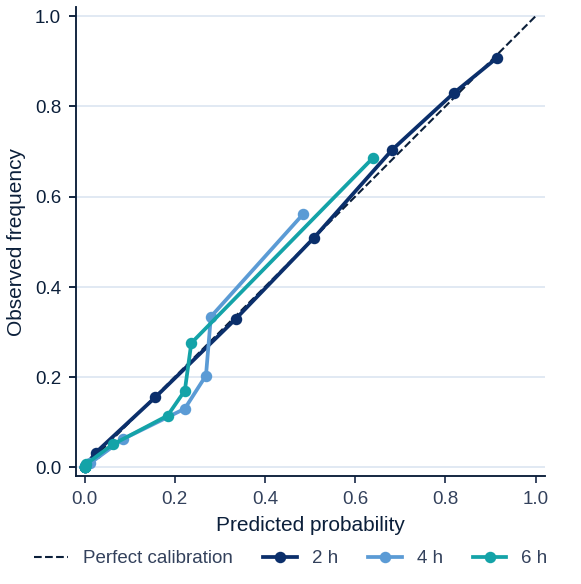

Figure 11: Calibrated action probabilities are reliable
Table 5: Calibration and discrimination of the action heads


,Decision time (h),Action,AUROC,ECE raw,ECE calibrated,Temperature,Slope,Bias
0,2,failure or persistence,0.924537,0.028867,0.005542,1.017226,1.292586,-0.084535
1,4,rebound,0.896703,0.023735,0.018004,1.004966,1.525036,0.723017
2,6,rebound,0.920191,0.011566,0.009475,1.032465,1.387535,0.470159


In [ ]:
#calibration of the action probabilities
@torch.no_grad()
def predict_model(model, x):
    model.eval(); result = [[] for _ in range(6)]
    for start in range(0, len(x), CFG['inference_batch']):
        out = model(x[start:start + CFG['inference_batch']].to(DEVICE))
        for dest, value in zip(result, out): dest.append(value.cpu())
    return [torch.cat(v) for v in result]

@torch.no_grad()
def predict_stage(stage, x):
    members = [predict_model(m, x) for m in MODELS[stage]]
    primary = members[0]                                   # class and endpoint heads: first member
    mean_prob = torch.stack([torch.sigmoid(o[4]) for o in members]).mean(0)
    ensemble_logit = torch.logit(mean_prob.clamp(1e-6, 1 - 1e-6))
    mean_hidden = torch.stack([o[5] for o in members]).mean(0)
    return primary[0], primary[1], primary[2], primary[3], ensemble_logit, mean_hidden

TEMPERATURES, ACTION_CAL, OOD = [], [], []
for stage in range(3):
    out = predict_stage(stage, FEATURES['temperature'][stage])
    logits, action_logit = out[0], out[4]
    labels = DATA['temperature']['label']; target = (labels == ACTION_CLASS[stage]).float()
    log_t = torch.zeros((), requires_grad=True)
    opt = torch.optim.LBFGS([log_t], lr=.1, max_iter=100)
    def closure_t():
        opt.zero_grad(); loss = F.cross_entropy(logits/log_t.exp().clamp(.05, 20.), labels); loss.backward(); return loss
    opt.step(closure_t); TEMPERATURES.append(float(log_t.detach().exp().clamp(.05, 20.)))
    raw_scale = torch.zeros((), requires_grad=True); bias = torch.zeros((), requires_grad=True)
    opt = torch.optim.LBFGS([raw_scale, bias], lr=.1, max_iter=150)
    def closure_a():
        opt.zero_grad(); scale = F.softplus(raw_scale) + 1e-4
        loss = F.binary_cross_entropy_with_logits(scale*action_logit + bias, target); loss.backward(); return loss
    opt.step(closure_a)
    ACTION_CAL.append((float(F.softplus(raw_scale.detach()) + 1e-4), float(bias.detach())))
    train_h = predict_stage(stage, FEATURES['train'][stage])[-1].numpy()
    est = LedoitWolf().fit(train_h)
    location = torch.tensor(est.location_, dtype=torch.float64); precision = torch.tensor(est.precision_, dtype=torch.float64)
    cal_h = predict_stage(stage, FEATURES['ood_calibration'][stage])[-1].double()
    diff = cal_h - location
    score = torch.einsum('bi,ij,bj->b', diff, precision, diff)
    rank = min(len(score), math.ceil((len(score) + 1)*CFG['ood_quantile']))
    OOD.append({'location': location, 'precision': precision, 'cutoff': float(score.sort().values[rank - 1])})
save_pt(ROOT/'models'/'calibration.pt', dict(run_id=RUN_ID, temperatures=TEMPERATURES,
        action_calibrators=ACTION_CAL, ood=OOD))

def infer_data(data):
    outputs, class_prob, action_prob, domain, scores = [], [], [], [], []
    for stage in range(3):
        x = core.features(data, CFG, CFG['hours'][stage], STATS[stage]['mean'], STATS[stage]['std'])
        out = predict_stage(stage, x); outputs.append(out)
        class_prob.append((out[0]/TEMPERATURES[stage]).softmax(-1))
        scale, b = ACTION_CAL[stage]; action_prob.append(torch.sigmoid(scale*out[4] + b))
        diff = out[-1].double() - OOD[stage]['location']
        score = torch.einsum('bi,ij,bj->b', diff, OOD[stage]['precision'], diff)
        scores.append(score); domain.append(score <= OOD[stage]['cutoff'])
    return dict(outputs=outputs, class_probability=class_prob, action_probability=action_prob,
                domain=domain, scores=scores)

# ---- result of this step: calibration quality on the (unseen-by-calibration) policy-tuning cohort ----
def ece(p, y, bins=10):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges[1:-1]), 0, bins - 1); total = 0.
    for b in range(bins):
        m = idx == b
        if m.any(): total += m.mean()*abs(p[m].mean() - y[m].mean())
    return total

tun = DATA['policy_tuning']; inf = infer_data(tun); rows = []
fig, ax = new_figure(FIG_W1*1.4, 3.9)
ax.plot([0, 1], [0, 1], color=BLUE["ink"], lw=1, ls="--", label="Perfect calibration", zorder=1)
for stage, (hour, c) in enumerate(zip(CFG['hours'], (BLUE["navy"], BLUE["sky"], ACCENT["teal"]))):
    y = (tun['label'] == ACTION_CLASS[stage]).numpy().astype(float)
    raw = torch.sigmoid(predict_stage(stage, FEATURES['policy_tuning'][stage])[4]).numpy()
    cal = inf['action_probability'][stage].numpy()
    rows.append({"Decision time (h)": f"{hour:g}", "Action": CFG['outcomes'][ACTION_CLASS[stage]].replace('_', ' '),
                 "AUROC": roc_auc_score(y, cal), "ECE raw": ece(raw, y), "ECE calibrated": ece(cal, y),
                 "Temperature": TEMPERATURES[stage], "Slope": ACTION_CAL[stage][0], "Bias": ACTION_CAL[stage][1]})
    edges = np.quantile(cal, np.linspace(0, 1, 11)); idx = np.clip(np.digitize(cal, edges[1:-1]), 0, 9)
    px = [cal[idx == b].mean() for b in range(10)]; py = [y[idx == b].mean() for b in range(10)]
    ax.plot(px, py, marker="o", ms=4.5, color=c, label=f"{hour:g} h", zorder=3)
ax.set_xlim(-.02, 1.02); ax.set_ylim(-.02, 1.02); ax.set_aspect("equal", adjustable="box")
style_axis(ax, "Predicted probability", "Observed frequency")
legend_below(fig, ax, ncol=4)
save_figure(fig, 11, "Calibrated action probabilities are reliable")
save_table(pd.DataFrame(rows), 5, "Calibration and discrimination of the action heads")

## Cell 9: Sequential threshold tuning, one-shot lockbox and policy freeze

**Run once.** This cell selects the decision thresholds, tests the complete policy on the untouched lockbox cohort, and freezes the policy. The lockbox is inspected a single time. If the candidate fails, the policy is not retuned, and new cohorts would be required.

**Selective policy.** A three-stage cascade with thresholds τ = (τ₂, τ₄, τ₆) applied to the calibrated action probabilities. A case is called *failure or persistence* at 2 h if p₂ₕ ≥ τ₂. Otherwise it is called *rebound* at 4 h if p₄ₕ ≥ τ₄, or at 6 h if p₆ₕ ≥ τ₆. Otherwise the policy abstains.

**Threshold selection (policy-tuning cohort only, 30,000 cases)**

- Thresholds are chosen from a grid of 60 equally spaced values in [0.70, 0.995].
- **Stage 1 (2 h).** Among thresholds whose calls reach a precision of at least 0.945 with at least 300 issued calls, choose the one with the largest coverage (ties go to the larger threshold).
- **Stage 2 (4 h and 6 h).** On the cases not already called failure, choose the pair (τ₄, τ₆) with the same precision and support requirements, by largest coverage, then smallest mean decision time, then larger thresholds.
- If no threshold is feasible, the procedure stops without a policy.
- The tuning precision (0.945) is deliberately stricter than the risk target (0.10 error), to leave a margin for sampling variability in the later exact bounds.

**One-shot lockbox (30,000 new cases).** The complete cascade is applied once. The candidate passes only if, for each action, the exact one-sided Clopper–Pearson upper bound at α = 0.025 is at most 0.10 and at least 300 calls were issued, and the total coverage is at least 5.5%. With α = 0.025 per action, the two bounds hold jointly with probability at least 0.95 (Bonferroni).

**Freeze.** The thresholds, the lockbox outcome and the run fingerprint are written to `policy.json`. If the candidate fails, `policy.json` records the failure and the cell stops with an error, so certification cannot be generated.

**Outputs.** `tables/failure_policy_tuning.csv` and `tables/rebound_policy_tuning.csv` (full tuning grids), `policy.json`, Figure 12 (precision–coverage trade-off on the tuning cohort) and Table 6 (frozen policy on the untouched lockbox).

**Notes**
- In the reported run, the selected thresholds were τ₂ = 0.950, τ₄ = 0.985 and τ₆ = 0.905. On the lockbox, the cascade issued 1,778 calls (coverage 5.93%) with 74 errors. The exact upper bounds were 6.97% for failure or persistence and 5.04% for rebound, so the policy passed and was frozen.
- In Figure 12, the rebound curve uses equal 4 h and 6 h thresholds for illustration. The selected pair is unequal (0.985 and 0.905), so its marker need not lie exactly on that curve.
- Re-running this cell re-inspects the lockbox and defeats the purpose of the pre-commitment. To reproduce the study from scratch, use a new output directory.

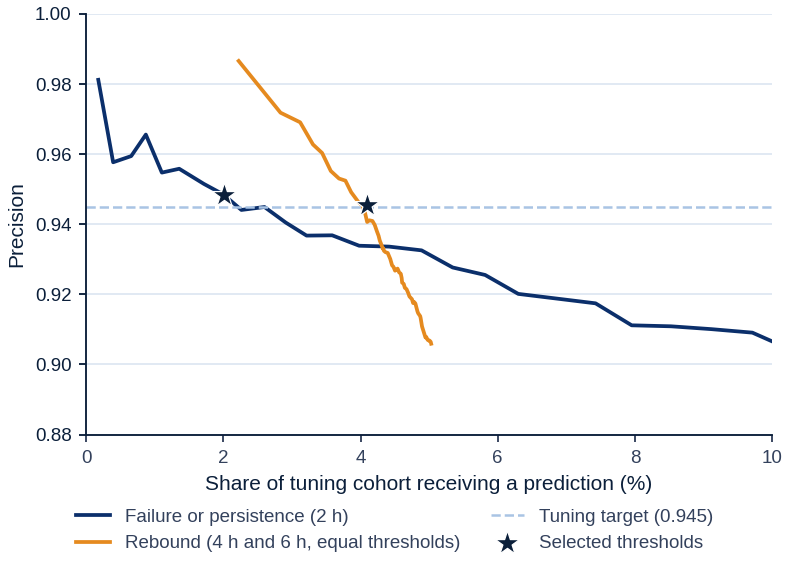

Figure 12: Precision and coverage trade-off on the tuning cohort
Table 6: Frozen policy on the untouched lockbox


,Action,Threshold(s),Issued,Errors,Precision,Error upper bound,Support gate,Risk gate
0,Failure or persistence,0.950,591,29,0.950931,0.069714,True,True
1,Rebound,0.985 / 0.905,1187,45,0.962089,0.050401,True,True
2,Whole cascade,-,1778,74,0.958380,NaN,True,NaN


Lockbox coverage 5.93% (required >= 5.5%) | all gates pass: True


In [ ]:
# sequential tuning, one-shot lockbox, whole-policy freeze
# RUN ONCE. The lockbox is inspected a single time; if it fails, the policy is not retuned (new cohorts would be required).
def error_ucb(errors, n, alpha):
    return 1. if n == 0 or errors == n else float(beta.ppf(1. - alpha, errors + 1, n - errors))

GRID = np.asarray(CFG['threshold_grid'])
tun = infer_data(DATA['policy_tuning']); truth = DATA['policy_tuning']['label'].numpy()
ap = [p.numpy() for p in tun['action_probability']]; N = len(truth)

# ---- stage 1: 2 h failure-or-persistence threshold ----
rows = []
for t in GRID:
    m = ap[0] >= t; n = int(m.sum()); e = int((truth[m] != 3).sum())
    rows.append(dict(threshold=float(t), issued=n, errors=e, precision=1 - e/n if n else np.nan, coverage=n/N))
FAIL = pd.DataFrame(rows); FAIL.to_csv(ROOT/'tables'/'failure_policy_tuning.csv', index=False)
feas = FAIL[(FAIL.issued >= CFG['minimum_action_support']) & (FAIL.precision >= CFG['tuning_precision'])]
if not len(feas): raise RuntimeError('No failure-or-persistence threshold satisfied the prespecified tuning gates.')
thr_fail = float(feas.sort_values(['coverage', 'threshold'], ascending=[False, False]).iloc[0].threshold)

# ---- stage 2: 4 h and 6 h rebound thresholds, among cases not already selected ----
remain = ap[0] < thr_fail; rows = []
for t4 in GRID:
    s4 = remain & (ap[1] >= t4)
    for t6 in GRID:
        s6 = remain & ~s4 & (ap[2] >= t6); m = s4 | s6; n = int(m.sum()); e = int((truth[m] != 1).sum())
        rows.append(dict(t4=float(t4), t6=float(t6), issued=n, errors=e, precision=1 - e/n if n else np.nan,
                         coverage=n/N, mean_hour=(4*s4.sum() + 6*s6.sum())/n if n else np.nan))
REB = pd.DataFrame(rows); REB.to_csv(ROOT/'tables'/'rebound_policy_tuning.csv', index=False)
feas = REB[(REB.issued >= CFG['minimum_action_support']) & (REB.precision >= CFG['tuning_precision'])]
if not len(feas): raise RuntimeError('No rebound threshold pair satisfied the prespecified tuning gates.')
best = feas.sort_values(['coverage', 'mean_hour', 't4', 't6'], ascending=[False, True, False, False]).iloc[0]
thr4, thr6 = float(best.t4), float(best.t6)
THRESHOLDS = {'stage_0': thr_fail, 'stage_1': thr4, 'stage_2': thr6}; ACTIVE = {'3': True, '1': True}

# ---- result of tuning: precision-coverage trade-off ----
sel_f = FAIL.loc[np.isclose(FAIL.threshold, thr_fail)].iloc[0]
fig, ax = new_figure(FIG_W1*1.5, 3.8)
f = FAIL[FAIL.issued >= 50]
ax.plot(f.coverage*100, f.precision, color=BLUE["navy"], label="Failure or persistence (2 h)")
diag = REB[np.isclose(REB.t4, REB.t6) & (REB.issued >= 50)].sort_values('coverage')
ax.plot(diag.coverage*100, diag.precision, color=ACCENT["amber"], label="Rebound (4 h and 6 h, equal thresholds)")
ax.axhline(CFG['tuning_precision'], color=BLUE["pale"], ls="--", lw=1.2, label=f"Tuning target ({CFG['tuning_precision']})")
ax.scatter([sel_f.coverage*100, best.coverage*100], [sel_f.precision, best.precision], marker="*", s=150,
           color=BLUE["ink"], edgecolor="white", linewidth=.6, zorder=4, label="Selected thresholds")
ax.set_xlim(0, 10); ax.set_ylim(0.88, 1.0)
style_axis(ax, "Share of tuning cohort receiving a prediction (%)", "Precision")
legend_below(fig, ax, ncol=2)
save_figure(fig, 12, "Precision and coverage trade-off on the tuning cohort")

# ---- one-shot lockbox with the complete frozen candidate ----
lock = infer_data(DATA['policy_lockbox']); ltruth = DATA['policy_lockbox']['label']
pred, stage_taken = core.cascade(lock['action_probability'], THRESHOLDS, CFG, ACTIVE)
rows = []
for cls, name, thr in ((3, 'Failure or persistence', f"{thr_fail:.3f}"), (1, 'Rebound', f"{thr4:.3f} / {thr6:.3f}")):
    m = pred == cls; n = int(m.sum()); e = int((ltruth[m] != cls).sum()); u = error_ucb(e, n, .025)
    rows.append({"Action": name, "Threshold(s)": thr, "Issued": n, "Errors": e,
                 "Precision": 1 - e/n if n else np.nan, "Error upper bound": u,
                 "Support gate": n >= CFG['minimum_action_support'], "Risk gate": u <= CFG['risk_target']})
issued = int((pred >= 0).sum()); errs = int((pred[pred >= 0] != ltruth[pred >= 0]).sum()); cov = issued/len(pred)
rows.append({"Action": "Whole cascade", "Threshold(s)": "-", "Issued": issued, "Errors": errs,
             "Precision": 1 - errs/issued if issued else np.nan, "Error upper bound": np.nan,
             "Support gate": cov >= CFG['lockbox_minimum_coverage'], "Risk gate": np.nan})
LOCK = pd.DataFrame(rows)
LOCK_PASS = bool(LOCK.iloc[:2]["Support gate"].all() and LOCK.iloc[:2]["Risk gate"].all() and cov >= CFG['lockbox_minimum_coverage'])
save_table(LOCK, 6, "Frozen policy on the untouched lockbox")
print(f"Lockbox coverage {cov*100:.2f}% (required >= {CFG['lockbox_minimum_coverage']*100:.1f}%) | all gates pass: {LOCK_PASS}")

policy = dict(run_id=RUN_ID, thresholds=THRESHOLDS, active_actions=ACTIVE, lockbox_passed=LOCK_PASS,
              lockbox_coverage=cov, tuning_precision=CFG['tuning_precision'], risk_target=CFG['risk_target'])
write_json(ROOT/'policy.json', policy)
if not LOCK_PASS:
    raise RuntimeError('The complete two-action candidate failed its untouched lockbox. '
                       'Certification is not generated; do not retune on lockbox results.')

## Cell 10: Certification cohort, stress cohorts and one-shot certification

**Run once, after the solver is frozen and the policy has passed its lockbox.** This cell generates the confirmatory cohort and the stress cohorts, then applies the frozen policy once to the certification cohort.

**Preconditions (asserted).** The solver manifest must be frozen and match the current run fingerprint, and `policy.json` must carry the same fingerprint and record a passed lockbox. If either check fails, the cell stops before any confirmatory data are generated.

**Cohort generation.** The certification cohort (60,000 cases) and the seven stress cohorts (10,000 cases each) are generated with the same sharded, seeded, digest-verified procedure as the development cohorts. They are generated only now, so that no confirmatory data existed while the models, calibrators and thresholds were being chosen. The seven stress cohorts are evaluated in the next cell.

**One-shot certification.** The frozen cascade is applied once to the certification cohort, with no retuning. For each action, the exact one-sided Clopper–Pearson upper bound on its conditional error rate is computed at α = 0.025. The policy is certified only if, for each action, the upper bound is at most the pre-specified 10% risk target and at least 300 calls were issued, and the total coverage (the share of cases receiving a call) is at least 5%.

**Outputs.** Table 7 (certification of the frozen policy), `certification.json` (run fingerprint, certification outcome, coverage and thresholds), and the certification and stress shards under `data/`.

**Notes**
- In the reported run, the frozen policy issued 3,531 calls (coverage 5.88%, required 5%) with 149 errors, a precision of 0.958. The exact upper bounds were 5.96% for failure or persistence (1,098 calls, 50 errors) and 4.93% for rebound (2,433 calls, 99 errors), both below the 10% target, so the policy was certified.
- The bounds hold when the policy is fixed before the evaluation cohort is drawn and the cases are independent draws from the simulator. They apply to the sampled certification distribution, not automatically to shifted or real-world data.
- The out-of-domain sentinel is not used by the confirmatory policy.

In [ ]:
#certification cohort and stress cohorts
# RUN ONCE, after the solver is frozen and the policy has passed its lockbox.
_m = json.loads((ROOT/'software'/'manifest.json').read_text())
assert _m['frozen'] and _m['run_id'] == RUN_ID, 'Set FREEZE_SOLVER = True in cell 2 and re-run that cell first.'
pol = json.loads((ROOT/'policy.json').read_text())
assert pol['run_id'] == RUN_ID and pol['lockbox_passed'], 'The frozen policy must have passed its lockbox.'
THR, ACT = pol['thresholds'], pol['active_actions']

FINAL = [x for x in COHORT_PLAN if x['name'] == 'certification' or x['name'].startswith('stress_')]
for spec in FINAL: generate_cohort(spec)
DATA_FINAL = {spec['name']: load_cohort(spec['name']) for spec in FINAL}

# ---- one-shot certification of the frozen policy ----
cert = DATA_FINAL['certification']; inf = infer_data(cert)
pred, _ = core.cascade(inf['action_probability'], THR, CFG, ACT)
rows = []
for cls, name in ((3, 'Failure or persistence'), (1, 'Rebound')):
    m = pred == cls; n = int(m.sum()); e = int((cert['label'][m] != cls).sum()); u = error_ucb(e, n, .025)
    rows.append({"Action": name, "Issued": n, "Errors": e, "Precision": 1 - e/n if n else np.nan,
                 "Error upper bound": u, "Support gate": n >= CFG['minimum_action_support'], "Risk gate": u <= CFG['risk_target']})
issued = int((pred >= 0).sum()); errs = int((pred[pred >= 0] != cert['label'][pred >= 0]).sum()); cov = issued/len(pred)
rows.append({"Action": "Whole cascade", "Issued": issued, "Errors": errs, "Precision": 1 - errs/issued if issued else np.nan,
             "Error upper bound": np.nan, "Support gate": cov >= CFG['minimum_coverage'], "Risk gate": np.nan})
CERT = pd.DataFrame(rows)
CERT_PASS = bool(CERT.iloc[:2]["Support gate"].all() and CERT.iloc[:2]["Risk gate"].all() and cov >= CFG['minimum_coverage'])
save_table(CERT, 7, "Certification of the frozen policy")
print(f"Certification coverage {cov*100:.2f}% (required >= {CFG['minimum_coverage']*100:.1f}%) | certified: {CERT_PASS}")
write_json(ROOT/'certification.json', dict(run_id=RUN_ID, certified=CERT_PASS, coverage=cov, thresholds=THR))

certification       512/60000  elapsed    3.3s  eta  388.1s  generated
certification      5632/60000  elapsed   36.7s  eta  357.5s  generated
certification     10752/60000  elapsed   69.9s  eta  322.9s  generated
certification     15872/60000  elapsed  102.9s  eta  288.7s  generated
certification     20992/60000  elapsed  135.8s  eta  255.1s  generated
certification     26112/60000  elapsed  169.3s  eta  222.4s  generated
certification     31232/60000  elapsed  202.1s  eta  188.8s  generated
certification     36352/60000  elapsed  235.1s  eta  155.7s  generated
certification     41472/60000  elapsed  268.2s  eta  122.5s  generated
certification     46592/60000  elapsed  301.1s  eta   89.3s  generated
certification     51712/60000  elapsed  334.6s  eta   56.3s  generated
certification     56832/60000  elapsed  367.8s  eta   23.2s  generated
certification     60000/60000  elapsed  389.7s  eta    0.0s  generated
stress_reference    512/10000  elapsed    3.3s  eta   61.8s  generated
stress

,Action,Issued,Errors,Precision,Error upper bound,Support gate,Risk gate
0,Failure or persistence,1098,50,0.954463,0.059597,True,True
1,Rebound,2433,99,0.959309,0.049319,True,True
2,Whole cascade,3531,149,0.957802,NaN,True,NaN


Certification coverage 5.88% (required >= 5.0%) | certified: True


## Cell 11: Stress battery with the frozen policy

This cell applies the frozen policy, unchanged, to seven pre-specified stress cohorts of 10,000 cases each. The analysis is secondary and exploratory: it never modifies the policy, the thresholds or the calibrators.

**Scenarios**

| Scenario | Perturbation |
|---|---|
| Reference | Nominal assay; independent replication of the certification conditions |
| Noise ×1.5 | Assay noise multiplied by 1.5 |
| 15% missing | Missingness raised from 5% to 15% |
| LOD +0.5 | Limit of detection raised by 0.5 log₁₀ |
| Fast growth, weak binding | Kinetic shift: growth rate drawn from the upper half of its range (0.7–1.2 h⁻¹) and adsorption exponents from the lower half (−12 to −10) |
| Low initial titres | Initial phage titre exponents drawn from the lower half of the prior (5 to 7.5) |
| Combined | All five perturbations together |

**Evaluation.** For each cohort and action, the cell reports the number of calls, the errors, the error rate and the exact one-sided Clopper–Pearson upper bound at α = 0.025. Each cohort is judged against the same gates as the certification, with the minimum number of calls scaled to the cohort size (300 × 10,000 / 60,000 = 50 per action): a support gate, a risk gate (upper bound at most 0.10 whenever calls are issued) and a coverage gate (at least 5%). The cell also reports the fraction of cases flagged by the exploratory out-of-domain sentinel at 6 h.

**Outputs.** `tables/stress_long_form.csv`, Table 8 (frozen policy under the stress battery) and Figure 13. In Figure 13, each scenario shows the error rate of the issued calls (dot) and its exact 97.5% upper bound (tick) for failure or persistence and for rebound, with the number of calls and the dashed 10% risk target.

**How to read the results.** The battery estimates behaviour over pre-specified perturbations. It does not establish validity for unrestricted out-of-distribution data. In the reported run, three of the seven cohorts passed all gates (reference, noise ×1.5 and the kinetic shift), and four failed. In no cohort did the point error rate of a well-populated action exceed 7.5%, so the loss of certification reflects fewer calls and wider bounds, not a collapse of precision. The sentinel flagged between 0.7% and 5.7% of cases and did not rank the scenarios by severity.

**Notes**
- A cohort with no calls for an action fails the support gate for that action, but not the risk gate, because no bound can be computed.
- The 10,000-case cohorts support fewer calls than the 60,000-case certification cohort, so their bounds are wider for the same error rate.

Support requirement for stress cohorts: 50 predictions per action (scaled from 300).
Table 8: Frozen policy under the stress battery


,Scenario,Coverage (%),Failure issued,Failure error [upper bound] (%),Rebound issued,Rebound error [upper bound] (%),Out-of-domain flag (%),Gates
0,reference,5.69,192,2.6 [5.97],377,3.4 [5.82],2.24,Pass
1,noise ×1.5,6.19,206,5.8 [9.95],413,7.0 [9.93],3.45,Pass
2,15% missing,5.04,143,5.6 [10.73],361,6.9 [10.05],5.68,"Fail: failure risk, rebound risk"
3,LOD +0.5,2.96,143,6.3 [11.61],153,6.5 [11.69],4.19,"Fail: failure risk, rebound risk, coverage"
4,"fast growth, weak binding",11.11,992,4.7 [6.25],119,4.2 [9.53],0.68,Pass
5,low initial titres,2.36,8,0.0 [36.94],228,7.5 [11.67],3.87,"Fail: failure support, failure risk, rebound risk, coverage"
6,combined,0.21,21,9.5 [30.38],0,-,2.31,"Fail: failure support, failure risk, rebound support, coverage"


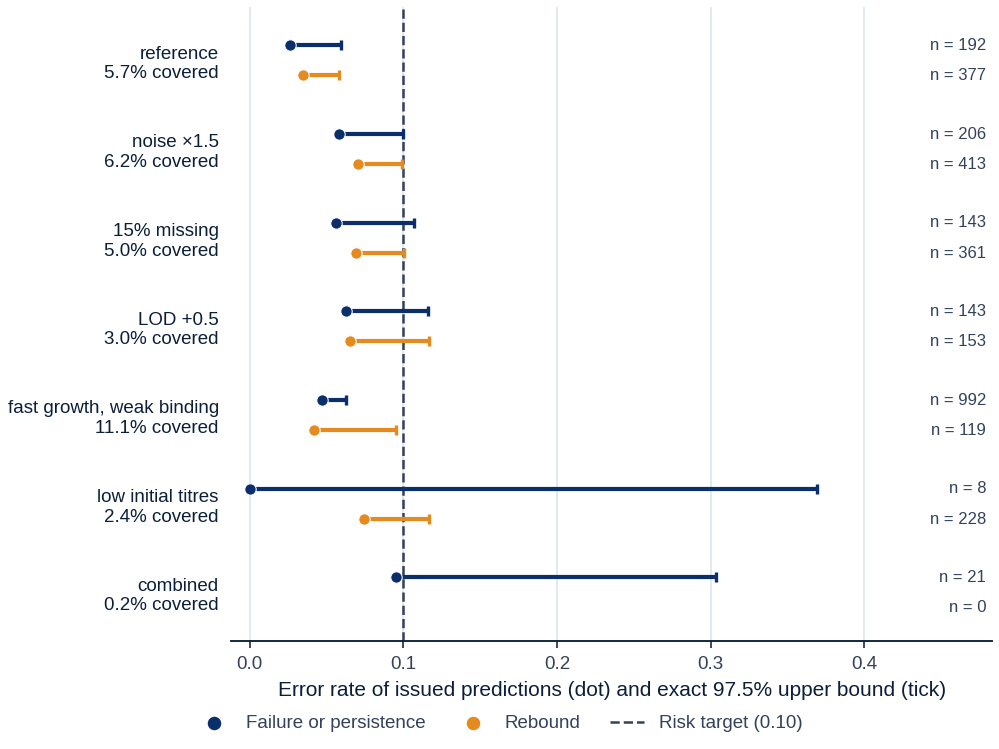

Figure 13: Risk and coverage of the frozen policy under assay and kinetic shift


In [ ]:
#stress battery with the frozen policy
STRESS = [n for n in DATA_FINAL if n.startswith('stress_')]
n_cert = len(DATA_FINAL['certification']['label'])
long_rows, paper_rows = [], []
for name in STRESS:
    d = DATA_FINAL[name]; inf = infer_data(d); N = len(d['label']); label = PRETTY[name].replace('Stress: ', '')
    pred, _ = core.cascade(inf['action_probability'], THR, CFG, ACT)
    cov = (pred >= 0).float().mean().item()*100
    min_sup = CFG['minimum_action_support']*N/n_cert
    row = {"Scenario": label, "Coverage (%)": round(cov, 2)}; reasons = []
    for cls, key, aname in ((3, "Failure", "Failure or persistence"), (1, "Rebound", "Rebound")):
        m = pred == cls; n = int(m.sum()); e = int((d['label'][m] != cls).sum()); u = error_ucb(e, n, .025) if n else np.nan
        sup = n >= min_sup; risk = bool(n > 0 and u <= CFG['risk_target'])
        long_rows.append({"Scenario": label, "Action": aname, "Issued": n, "Errors": e, "Cohort": N,
                          "Error rate": e/n if n else np.nan, "Error upper bound": u, "Support gate": sup, "Risk gate": risk})
        row[f"{key} issued"] = n
        row[f"{key} error [upper bound] (%)"] = f"{100*e/n:.1f} [{100*u:.2f}]" if n else "-"
        if not sup: reasons.append(f"{key.lower()} support")
        if n > 0 and not risk: reasons.append(f"{key.lower()} risk")
    if cov < CFG['minimum_coverage']*100: reasons.append("coverage")
    row["Out-of-domain flag (%)"] = round(float((~inf['domain'][2]).float().mean())*100, 2)
    row["Gates"] = "Pass" if not reasons else "Fail: " + ", ".join(reasons)
    paper_rows.append(row)
LONG = pd.DataFrame(long_rows); LONG.to_csv(ROOT/'tables'/'stress_long_form.csv', index=False)
PAPER = pd.DataFrame(paper_rows)
print(f"Support requirement for stress cohorts: {CFG['minimum_action_support']*10000/n_cert:.0f} predictions per action (scaled from {CFG['minimum_action_support']}).")
save_table(PAPER, 8, "Frozen policy under the stress battery")

# ---- result: risk and coverage together, per scenario and action ----
fig, ax = new_figure(FIG_W1*1.9, 5.0)
labels = [f"{r['Scenario']}\n{r['Coverage (%)']:.1f}% covered" for _, r in PAPER.iterrows()]
ypos = {s: i for i, s in enumerate(PAPER["Scenario"])}
style = {"Failure or persistence": (BLUE["navy"], -.17), "Rebound": (ACCENT["amber"], .17)}
xmax = float(LONG["Error upper bound"].max())*1.0 + .11
for aname, (c, off) in style.items():
    for _, r in LONG[LONG.Action == aname].iterrows():
        y = ypos[r.Scenario] + off
        ax.text(xmax, y, f"n = {int(r.Issued)}", ha="right", va="center", fontsize=8, color=BLUE["text"])
        if r.Issued == 0: continue
        ax.plot([r["Error rate"], r["Error upper bound"]], [y, y], color=c, lw=2, solid_capstyle="round", zorder=3)
        ax.scatter([r["Error rate"]], [y], s=30, color=c, edgecolor="white", linewidth=.5, zorder=4)
        ax.scatter([r["Error upper bound"]], [y], s=26, marker="|", color=c, linewidth=1.6, zorder=4)
    ax.scatter([], [], s=30, color=c, label=aname)
ax.axvline(CFG['risk_target'], color=BLUE["text"], ls="--", lw=1.2, label=f"Risk target ({CFG['risk_target']:.2f})")
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
ax.set_ylim(len(labels) - .45, -.6); ax.set_xlim(-.012, xmax + .004)
ax.tick_params(axis="y", length=0, pad=6); ax.spines["left"].set_visible(False); ax.grid(axis="x", zorder=0)
ax.set_xlabel("Error rate of issued predictions (dot) and exact 97.5% upper bound (tick)")
legend_below(fig, ax, ncol=3)
save_figure(fig, 13, "Risk and coverage of the frozen policy under assay and kinetic shift")

## Cell 12: Descriptive performance on the certification cohort

This cell reports how well the models predict outcomes on the 60,000-case certification cohort, independently of the selective policy. The metrics are descriptive and are **not** part of the certification, which rests only on the exact error bounds of the frozen policy.

**Outcome prediction (four classes).** For each stage, the cell reports accuracy, macro-F1, the multiclass Brier score (the mean over cases of the sum of squared probability errors over the four classes) and log-loss. It also reports the AUROC of the calibrated action probability: failure or persistence at 2 h and rebound at 4 and 6 h.

**24 h endpoint.** The mixture-density output is converted back to log₁₀ units. The cell reports the mean absolute error of the mixture median, the continuous ranked probability score (CRPS, using its closed form for Gaussian mixtures), and the empirical coverage and mean width of the central 90% interval (5th to 95th percentile, found by 60 bisection steps on the mixture distribution function). Interval coverage must be read together with width, because wide intervals can cover most outcomes while remaining uninformative.

**Baselines**

- *Training prevalence*: every case receives the class frequencies of the training cohort.
- *Initial assay only*: a gradient-boosted tree classifier (scikit-learn histogram gradient boosting, 200 iterations, seed 20261002) that uses only the 0 h measurements (standardised baseline values of the three channels and their observation indicators), trained on the same 90,000 training cases.

**Fate of each true outcome (Table 10).** For each true outcome, the share of cases that the frozen policy called failure, called rebound or abstained on.

**Outputs.** Table 9 (prediction performance on the certification cohort) and Table 10 (fate of each true outcome under the frozen policy).

**Reading the results**
- In the reported run, four-class accuracy rose from 0.633 at 2 h to 0.677 at 4 h and 0.723 at 6 h, against 0.345 for the prevalence baseline and 0.452 for the initial-assay baseline. The action AUROC was 0.923, 0.901 and 0.926. The endpoint MAE fell from 2.03 to 1.80 and 1.56 log₁₀ units, with 90% interval coverage of 0.906, 0.912 and 0.906 and mean widths of 8.1, 7.4 and 6.2 log₁₀ units.
- The policy called 5.1% of true failures and 29.7% of true rebounds, and abstained on most other cases. Wrong-type calls were rare (at most 0.47% of any class).

**Notes**
- These whole-cohort metrics have different denominators from the selective precision reported in the certification.
- The initial-assay baseline is deliberately simple. It shows that the early time course carries information beyond the baseline measurement, not that Transformer ensembles outperform other sequence models.
- Class and endpoint outputs come from the first ensemble member, with temperature-scaled class probabilities.

In [ ]:
#performance on the certification cohort (descriptive)
from sklearn.ensemble import HistGradientBoostingClassifier
cert = DATA_FINAL['certification']; truth = cert['label'].numpy(); inf = infer_data(cert); n = len(truth)
onehot = np.eye(4)[truth]; y_end = cert['endpoint'].double()
prev = (torch.bincount(DATA['train']['label'], minlength=4).float()/len(DATA['train']['label'])).numpy()

def class_metrics(p):
    pred = p.argmax(1)
    return {"Accuracy": float((pred == truth).mean()),
            "Macro-F1": float(f1_score(truth, pred, labels=[0, 1, 2, 3], average='macro', zero_division=0)),
            "Brier": float(((p - onehot)**2).sum(1).mean()),
            "Log loss": float(log_loss(truth, np.clip(p, 1e-9, 1), labels=[0, 1, 2, 3]))}

def mix_params(out):
    w = out[1].softmax(-1).double(); m = out[2].double()*END_STD.double() + END_MEAN.double(); s = out[3].double()*END_STD.double()
    return w, m, s
def mix_cdf(x, w, m, s): return (w*.5*(1 + torch.erf((x[:, None] - m)/(s*math.sqrt(2))))).sum(1)
def mix_quantile(w, m, s, q):
    lo = (m - 12*s).min(1).values; hi = (m + 12*s).max(1).values
    for _ in range(60):
        mid = (lo + hi)/2; below = mix_cdf(mid, w, m, s) < q
        lo = torch.where(below, mid, lo); hi = torch.where(below, hi, mid)
    return (lo + hi)/2
def abs_normal_mean(d, s): return s*math.sqrt(2/math.pi)*torch.exp(-.5*(d/s)**2) + d*torch.erf(d/(s*math.sqrt(2)))
def crps(w, m, s, y):
    first = (w*abs_normal_mean(y[:, None] - m, s)).sum(1)
    d = m[:, :, None] - m[:, None, :]; sd = torch.sqrt(s[:, :, None]**2 + s[:, None, :]**2)
    pair = (w[:, :, None]*w[:, None, :]*abs_normal_mean(d, sd)).sum((1, 2))
    return first - .5*pair

rows = [{"Model": "Training prevalence", **class_metrics(np.tile(prev, (n, 1)))}]
def x0(d):
    z = torch.where(d['observed'][:, 0, :], (d['values'][:, 0, :] - STATS[0]['mean'])/STATS[0]['std'], torch.zeros(len(d['label']), 3))
    return torch.cat((z, d['observed'][:, 0, :].float()), 1).numpy()
Xtr = np.concatenate([x0(DATA['train']), x0(DATA['robust_train'])])
ytr = np.concatenate([DATA['train']['label'].numpy(), DATA['robust_train']['label'].numpy()])
gb = HistGradientBoostingClassifier(max_iter=200, random_state=SEED).fit(Xtr, ytr)
rows.append({"Model": "Initial assay only (0 h), gradient boosting", **class_metrics(gb.predict_proba(x0(cert)))})
for k, hour in enumerate(CFG['hours']):
    out = inf['outputs'][k]; w, m, s = mix_params(out)
    q05, q50, q95 = (mix_quantile(w, m, s, q) for q in (.05, .5, .95))
    rows.append({"Model": f"Transformer ensemble, {hour:g} h", **class_metrics(inf['class_probability'][k].numpy()),
                 "Action AUROC": float(roc_auc_score(truth == ACTION_CLASS[k], inf['action_probability'][k].numpy())),
                 "Endpoint MAE": float((q50 - y_end).abs().mean()), "Endpoint CRPS": float(crps(w, m, s, y_end).mean()),
                 "90% interval coverage": float(((y_end >= q05) & (y_end <= q95)).double().mean()),
                 "Mean interval width": float((q95 - q05).mean())})
save_table(pd.DataFrame(rows).round(3).fillna("-"), 9, "Prediction performance on the certification cohort")

# ---- what happens to each true outcome under the frozen policy ----
pred, _ = core.cascade(inf['action_probability'], THR, CFG, ACT); pred = pred.numpy()
names = ['Sustained clearance', 'Rebound', 'Partial control', 'Failure or persistence']; rows = []
for c in range(4):
    sel = pred[truth == c]
    rows.append({"True outcome": names[c], "Cases": int(len(sel)), "Predicted failure (%)": 100*np.mean(sel == 3),
                 "Predicted rebound (%)": 100*np.mean(sel == 1), "Abstained (%)": 100*np.mean(sel < 0)})
save_table(pd.DataFrame(rows).round(2), 10, "Fate of each true outcome under the frozen policy")

Table 9: Prediction performance on the certification cohort


,Model,Accuracy,Macro-F1,Brier,Log loss,Action AUROC,Endpoint MAE,Endpoint CRPS,90% interval coverage,Mean interval width
0,Training prevalence,0.345,0.128,0.724,1.331,-,-,-,-,-
1,"Initial assay only (0 h), gradient boosting",0.452,0.388,0.663,1.212,-,-,-,-,-
2,"Transformer ensemble, 2 h",0.633,0.590,0.478,0.824,0.923,2.025,1.409,0.906,8.086
3,"Transformer ensemble, 4 h",0.677,0.640,0.428,0.726,0.901,1.798,1.258,0.912,7.35
4,"Transformer ensemble, 6 h",0.723,0.691,0.375,0.633,0.926,1.558,1.09,0.906,6.238


Table 10: Fate of each true outcome under the frozen policy


,True outcome,Cases,Predicted failure (%),Predicted rebound (%),Abstained (%)
0,Sustained clearance,13720,0.01,0.02,99.96
1,Rebound,7863,0.01,29.68,70.30
2,Partial control,17717,0.27,0.47,99.26
3,Failure or persistence,20700,5.06,0.06,94.88


## Cell 13: Erlang-chain solver for the held-out latent-period mechanism

The training simulator assumes a deterministic latent period. This cell builds a second solver that replaces it with a distributed latent period of the same mean, so the frozen policy can be tested against a structural change in the mechanism. The solver is a **separate module** (`software/cocktail_chain.py`). The frozen core solver is not modified, so its fingerprint and all data generated from it stay valid.

**Model.** For each phage, infected cells are held in a chain of *k* stages. In each step a fraction f = kΔt/L of the cells in each stage advances to the next stage, and cells leaving the last stage lyse and release their burst. This is the discrete-time analogue of the linear chain trick for gamma-distributed dwell times. The sojourn time in each stage is geometric, so the latent period is a sum of *k* such times with mean L and, as Δt → 0, an Erlang distribution with coefficient of variation 1/√k. At the 1 min step used here, the realised coefficient of variation is √((1 − f)/k), slightly below the nominal value (for example 0.30 instead of 0.35 for k = 8 and L = 30 min). The nominal values (0.35, 0.50, 0.71 and 1.00 for k = 8, 4, 2, 1) are used as labels only. The scheme requires kΔt ≤ L for both phages.

**What differs from the core solver**
- The latent period is distributed instead of fixed.
- Cross-superinfection is omitted. Phage A adsorbs to susceptible and B-resistant cells only, and phage B to susceptible and A-resistant cells only.
- A susceptible cell infected by both phages in the same step is assigned to the phage with the shorter mean latent period (half to each if equal).
- All other processes and constants are shared with the core solver: Monod growth with resource depletion, resistant classes, mutation, phage decay, washout and adsorption.

**Exactness check (asserted).** For k = L/Δt, the transition probability equals one, the chain becomes a deterministic shift register, and the solver must coincide with the fixed-delay core solver without superinfection. The cell asserts a maximum difference below 10⁻⁶ log₁₀ units in double precision on 16 random draws, for latent periods (30, 20) min and (25, 25) min. If the assertion fails, the cell stops.

**Magnitude of the manipulation (Table 11).** On 64 random parameter draws, the cell compares each Erlang model (k = 8, 4, 2, 1) with the fixed-delay model and reports the median over cases of the maximum difference in log₁₀ bacterial titre, and the percentage of cases whose outcome label is unchanged. In the reported run, the median maximum difference rose from 1.40 log₁₀ units at k = 8 to 3.70 at k = 1.

**Outputs.** `software/cocktail_chain.py` (chain solver source, SHA-256 beginning 7788c1f3ef12988d), the printed confirmation that the frozen core is unchanged, and Table 11 (latent-period distribution and its effect on trajectories and outcomes).

**Notes**
- The text of `CHAIN_SOURCE` is hashed and archived. Do not edit it after the run.
- Table 11 uses only 64 draws, so its outcome-agreement percentages have a granularity of about 1.6 percentage points. Quote the manipulation's effect on outcome labels in the manuscript only with that sample size stated, or compute it on the 10,000-case paired cohorts used in the next cells.

In [ ]:
#Erlang-chain solver (held-out latent-period mechanism)
# Separate module: the frozen core (cocktail_core.py) is NOT modified, so its fingerprint and all generated data stay valid.
CHAIN_SOURCE = r"""
import math
import numpy as np
import torch

PHYS_DEFAULT = dict(ks=5., c_in=100., c0=None, eps=2e-6, resistant_init=(1e-7, 1e-7, 1e-14),
                    growth_ratio=(1., .9, .9, .8), mutation=True)

def simulate_chain(theta, minutes, k=(16, 16), device='cpu', dt_min=1., dtype=torch.float32, phys=None, return_states=False):
    # Latent period = Erlang(k) with mean L: a chain of k infected stages, each left with probability k*dt/L per step.
    # k = L/dt (probability 1) is a deterministic shift register and equals the fixed-delay solver without superinfection.
    p = {**PHYS_DEFAULT, **(phys or {})}
    kA, kB = (int(k), int(k)) if isinstance(k, (int, np.integer)) else (int(k[0]), int(k[1]))
    theta = theta.to(device=device, dtype=dtype)
    assert theta.ndim == 2 and theta.shape[1] == 15 and kA >= 1 and kB >= 1
    times = np.asarray(minutes, dtype=float)
    assert times[0] == 0 and np.all(np.diff(times) > 0)
    sample_steps = np.rint(times/dt_min).astype(int)
    assert np.allclose(sample_steps*dt_min, times)
    n = len(theta)
    la, lb = theta[:, 4].clamp_min(1e-3), theta[:, 5].clamp_min(1e-3)
    if max(kA*dt_min - float(la.min().detach()), kB*dt_min - float(lb.min().detach())) > 1e-9:
        raise ValueError('k*dt_min must not exceed the shortest latent period')
    fa, fb = (kA*dt_min/la).clamp(max=1.), (kB*dt_min/lb).clamp(max=1.)
    wa = (la < lb).to(dtype) + .5*(la == lb).to(dtype); wb = 1. - wa
    ba, bb = theta[:, 6], theta[:, 7]
    mua, mub = 10.**theta[:, 8], 10.**theta[:, 9]
    if not p['mutation']:
        mua, mub = torch.zeros_like(mua), torch.zeros_like(mub)
    flow, da, db = theta[:, 10], theta[:, 11], theta[:, 12]
    aa, ab = 10.**theta[:, 2], 10.**theta[:, 3]
    pa, pb = 10.**theta[:, 13], 10.**theta[:, 14]
    ks, c_in, eps = float(p['ks']), float(p['c_in']), float(p['eps'])
    growth = theta[:, 1, None]*theta.new_tensor(list(p['growth_ratio']))
    ra, rb, rab = p['resistant_init']
    active = 10.**theta[:, 0, None]*theta.new_tensor([1. - ra - rb - rab, ra, rb, rab])
    nutrient = theta.new_full((n,), c_in if p['c0'] is None else float(p['c0']))
    IA, IB = theta.new_zeros((n, kA)), theta.new_zeros((n, kB))
    dt_h = dt_min/60.; result, states = [], []

    def record():
        infected = IA.sum(1) + IB.sum(1)
        result.append(torch.stack((active.sum(1) + infected, pa, pb), -1).clamp_min(1e-30).log10())
        if return_states:
            states.append(torch.cat((active, infected[:, None]), 1).clamp_min(1e-30).log10())
    record(); cursor = 1
    for step in range(int(sample_steps[-1])):
        nutrient = nutrient + dt_h*flow*(c_in - nutrient)
        monod = nutrient/(nutrient + ks).clamp_min(1e-30)
        new = active*growth*monod[:, None]*dt_h
        active = active + new - active*flow[:, None]*dt_h
        nutrient = (nutrient - eps*new.sum(1)).clamp_min(0.)
        ma, mb = new[:, 0]*mua, new[:, 0]*mub; mab = new[:, 0]*mua*mub
        scale = torch.minimum(torch.ones_like(ma), new[:, 0]/(ma + mb + mab).clamp_min(1e-30))
        ma, mb, mab = ma*scale, mb*scale, mab*scale
        sa, sb = new[:, 1]*mub, new[:, 2]*mua
        active = torch.stack((active[:, 0] - ma - mb - mab, active[:, 1] + ma - sa,
                              active[:, 2] + mb - sb, active[:, 3] + mab + sa + sb), 1).clamp_min(0.)
        survival = (1. - flow*dt_h).clamp_min(0.)
        IA, IB = IA*survival[:, None], IB*survival[:, None]
        oA, oB = IA*fa[:, None], IB*fb[:, None]
        IA = IA - oA + torch.cat((torch.zeros_like(oA[:, :1]), oA[:, :-1]), 1)
        IB = IB - oB + torch.cat((torch.zeros_like(oB[:, :1]), oB[:, :-1]), 1)
        pa = pa + ba*oA[:, -1]; pb = pb + bb*oB[:, -1]
        pa = pa*(1. - (da + flow)*dt_h).clamp_min(0.)
        pb = pb*(1. - (db + flow)*dt_h).clamp_min(0.)
        pool_a = active[:, 0] + active[:, 2]; pool_b = active[:, 0] + active[:, 1]
        raw_a, raw_b = aa*pool_a*pa*dt_min, ab*pool_b*pb*dt_min
        bound_a, bound_b = torch.minimum(raw_a, pa), torch.minimum(raw_b, pb)
        hit_a = torch.minimum(bound_a, pool_a).clamp_min(0.); hit_b = torch.minimum(bound_b, pool_b).clamp_min(0.)
        pa, pb = (pa - bound_a).clamp_min(0.), (pb - bound_b).clamp_min(0.)
        a_s = hit_a*active[:, 0]/pool_a.clamp_min(1e-30); a_r = hit_a*active[:, 2]/pool_a.clamp_min(1e-30)
        b_s = hit_b*active[:, 0]/pool_b.clamp_min(1e-30); b_r = hit_b*active[:, 1]/pool_b.clamp_min(1e-30)
        both = a_s*b_s/active[:, 0].clamp_min(1e-30)
        only_a, only_b = (a_s - both).clamp_min(0.), (b_s - both).clamp_min(0.)
        factor = torch.minimum(torch.ones_like(both), active[:, 0]/(only_a + only_b + both).clamp_min(1e-30))
        only_a, only_b, both = only_a*factor, only_b*factor, both*factor
        a_r, b_r = torch.minimum(a_r, active[:, 2]), torch.minimum(b_r, active[:, 1])
        active = torch.stack((active[:, 0] - only_a - only_b - both, active[:, 1] - b_r,
                              active[:, 2] - a_r, active[:, 3]), 1).clamp_min(0.)
        IA = torch.cat((IA[:, :1] + (only_a + a_r + both*wa)[:, None], IA[:, 1:]), 1)
        IB = torch.cat((IB[:, :1] + (only_b + b_r + both*wb)[:, None], IB[:, 1:]), 1)
        if cursor < len(sample_steps) and step + 1 == sample_steps[cursor]:
            record(); cursor += 1
    out = torch.stack(result, 1)
    if not torch.isfinite(out).all(): raise FloatingPointError('Nonfinite chain-solver output')
    return (out, torch.stack(states, 1)) if return_states else out
"""
import ast, importlib
ast.parse(CHAIN_SOURCE)
CHAIN_PATH = ROOT/'software'/'cocktail_chain.py'; CHAIN_PATH.write_text(CHAIN_SOURCE)
import cocktail_chain as chain
chain = importlib.reload(chain)
print('Chain solver SHA-256:', sha256(CHAIN_PATH)[:16], '| frozen core unchanged:', sha256(ROOT/'software'/'cocktail_core.py')[:16] == CORE_SHA[:16])

bnd = torch.tensor(BOUNDS, dtype=torch.float64); g = torch.Generator().manual_seed(SEED + 77)

# ---- exactness: k = L/dt makes the chain a deterministic shift register = the fixed-delay solver (no superinfection) ----
mins24 = list(range(0, 24*60 + 1, 60)); worst = 0.
for la_, lb_ in ((30., 20.), (25., 25.)):
    th = bnd[:, 0] + torch.rand(16, 15, generator=g).double()*(bnd[:, 1] - bnd[:, 0]); th[:, 4], th[:, 5] = la_, lb_
    fixed = core.simulate(th, mins24, dt_min=1., dtype=torch.float64, phys=dict(superinfection=False))
    erl = chain.simulate_chain(th, mins24, k=(int(la_), int(lb_)), dt_min=1., dtype=torch.float64)
    worst = max(worst, float((fixed - erl).abs().max()))
assert worst < 1e-6, f"Chain solver does not reproduce the fixed-delay solver (max difference {worst:.2e})"

# ---- the held-out mechanism: how far does a distributed latent period move trajectories and outcomes? ----
thc = (bnd[:, 0] + torch.rand(64, 15, generator=g).double()*(bnd[:, 1] - bnd[:, 0])).float()
thc[:, 4], thc[:, 5] = thc[:, 4].round().clamp(10, 60), thc[:, 5].round().clamp(10, 60)
full = CFG['full_minutes']
fixed = core.simulate(thc, full, dt_min=1., phys=dict(superinfection=False)); lab_fixed = core.outcomes(fixed, full)
rows = [{"Latent-period model": "Fixed delay, as a chain with k = L/dt", "Latent-period CV": 0.0,
         "Median max |difference| in bacterial titre (log10)": worst, "Outcome agreement with fixed delay (%)": 100.0}]
for kk in (8, 4, 2, 1):
    erl = chain.simulate_chain(thc, full, k=(kk, kk), dt_min=1.); lab = core.outcomes(erl, full)
    rows.append({"Latent-period model": f"Erlang, k = {kk}", "Latent-period CV": round(1/math.sqrt(kk), 2),
                 "Median max |difference| in bacterial titre (log10)": float((erl[:, :, 0] - fixed[:, :, 0]).abs().amax(1).median()),
                 "Outcome agreement with fixed delay (%)": float((lab == lab_fixed).float().mean()*100)})
save_table(pd.DataFrame(rows).round(2), 11, "Latent-period distribution and its effect on trajectories and outcomes")

Chain solver SHA-256: 7788c1f3ef12988d | frozen core unchanged: True
Table 11: Latent-period distribution and its effect on trajectories and outcomes


,Latent-period model,Latent-period CV,Median max |difference| in bacterial titre (log10),Outcome agreement with fixed delay (%)
0,"Fixed delay, as a chain with k = L/dt",0.00,0.00,100.00
1,"Erlang, k = 8",0.35,1.40,95.31
2,"Erlang, k = 4",0.50,2.25,95.31
3,"Erlang, k = 2",0.71,2.90,92.19
4,"Erlang, k = 1",1.00,3.70,89.06


## Cell 14: Held-out latent-period cohorts, frozen-policy evaluation and matched-model control

This cell tests the frozen policy against a structural change in the mechanism, and then asks how much of any resulting loss is due to training on the wrong mechanism. The policy, thresholds and calibrators are never modified.

### Part A: Held-out mechanism cohorts (paired design)

- **Cohorts.** Five held-out cohorts of 10,000 cases each (seed 20263000): a fixed-delay control (core solver with superinfection switched off) and the Erlang-chain solver with k = 8, 4, 2 and 1 for both phages.
- **Paired design.** Every cohort uses the same parameter draws (latent periods rounded to whole minutes) and the same assay-noise seeds. Only the latent-period mechanism differs, so differences between cohorts are attributable to the mechanism alone. The control also has superinfection off, so the control and the chain cohorts differ only in the latent-period distribution.
- **Evaluation.** The frozen policy is applied unchanged and judged against the certification gates, with the minimum number of calls scaled to the cohort size (50 per action), coverage of at least 5%, and the exact one-sided upper bound at α = 0.025 whenever calls are issued. The exploratory sentinel flag at 6 h is also reported.
- **Outputs.** Table 13 (frozen policy under a distributed latent period), `tables/heldout_long_form.csv`, and Figure 14 (error rate and exact upper bound of failure and rebound calls as latent-period variability increases).

### Part B: Matched-model control

- **Question.** If a loss appears under mechanism shift, is it because the model was trained on the wrong mechanism, or because the early observations carry less information?
- **Design.** For Erlang k = 4 and k = 1, a single-member model of the same architecture and objective is trained on data generated under the test mechanism itself: 60,000 training cases, 30,000 robust-training cases and 10,000 validation cases, with the same parameter draws and noise seeds as the original training and validation cohorts. Only the 2 h failure head and the 6 h rebound head are trained (AdamW, patience of 12 epochs, at most 100 epochs).
- **Comparison.** The original models (trained on the fixed delay) and the matched models are compared on the held-out cohort of the same mechanism by AUROC and average precision. For the fixed-delay control, both columns are the same original model.
- **Output.** Table 15 (cost of training on the wrong latent-period mechanism).

### How to read the results

- A fall in the number of calls with stable precision means the policy becomes quiet rather than wrong. A gate that fails because the bound widens as calls become few reflects fewer calls, not a collapse of precision.
- If matched training recovers part of the AUROC but not all of it, the loss has two components: a part removed by training on the correct mechanism, and a part that reflects genuinely less informative early observations.
- In the reported run, rebound calls fell from 374 at fixed delay to 240, 131, 54 and 17 as the coefficient of variation rose from 0.35 to 1.00, while failure calls stayed between 182 and 188. Matched training recovered AUROC by 0.022 (failure) and 0.011 (rebound) at k = 4, and by 0.078 and 0.038 at k = 1, without returning to the fixed-delay level.

### Notes

- Average precision depends on prevalence, which changes with the mechanism, so it is compared within a mechanism only.
- The matched models are single networks, whereas the original models are three-member ensembles. The matched-model probabilities are uncalibrated, which does not affect AUROC or average precision because both depend only on ranking.
- The nominal coefficients of variation (0.35, 0.50, 0.71, 1.00) are labels. The realised values at a 1 min step are slightly lower.
- This cell does not compute bootstrap intervals for the AUROC differences.

heldout_fixed               512/10000  elapsed    3.3s  generated
heldout_fixed              5632/10000  elapsed   36.3s  generated
heldout_fixed             10000/10000  elapsed   65.5s  generated
heldout_k8                  512/10000  elapsed    1.3s  generated
heldout_k8                 5632/10000  elapsed   14.3s  generated
heldout_k8                10000/10000  elapsed   26.0s  generated
heldout_k4                  512/10000  elapsed    1.3s  generated
heldout_k4                 5632/10000  elapsed   13.6s  generated
heldout_k4                10000/10000  elapsed   24.9s  generated
heldout_k2                  512/10000  elapsed    1.2s  generated
heldout_k2                 5632/10000  elapsed   12.9s  generated
heldout_k2                10000/10000  elapsed   23.5s  generated
heldout_k1                  512/10000  elapsed    1.1s  generated
heldout_k1                 5632/10000  elapsed   12.7s  generated
heldout_k1                10000/10000  elapsed   22.9s  generated
Table 13: 

,Mechanism,Latent-period CV,Coverage (%),Failure issued,Failure error [upper bound] (%),Rebound issued,Rebound error [upper bound] (%),Out-of-domain flag (%),Gates
0,Fixed delay (control),0.00,5.62,188,3.7 [7.52],374,3.2 [5.54],2.38,Pass
1,Erlang k = 8,0.35,4.27,187,3.7 [7.56],240,3.8 [7.00],2.14,Fail: coverage
2,Erlang k = 4,0.50,3.16,185,3.2 [6.93],131,3.1 [7.63],1.83,Fail: coverage
3,Erlang k = 2,0.71,2.39,185,3.8 [7.64],54,3.7 [12.75],1.63,"Fail: rebound risk, coverage"
4,Exponential (k = 1),1.00,1.99,182,3.8 [7.76],17,0.0 [19.51],1.16,"Fail: rebound support, rebound risk, coverage"


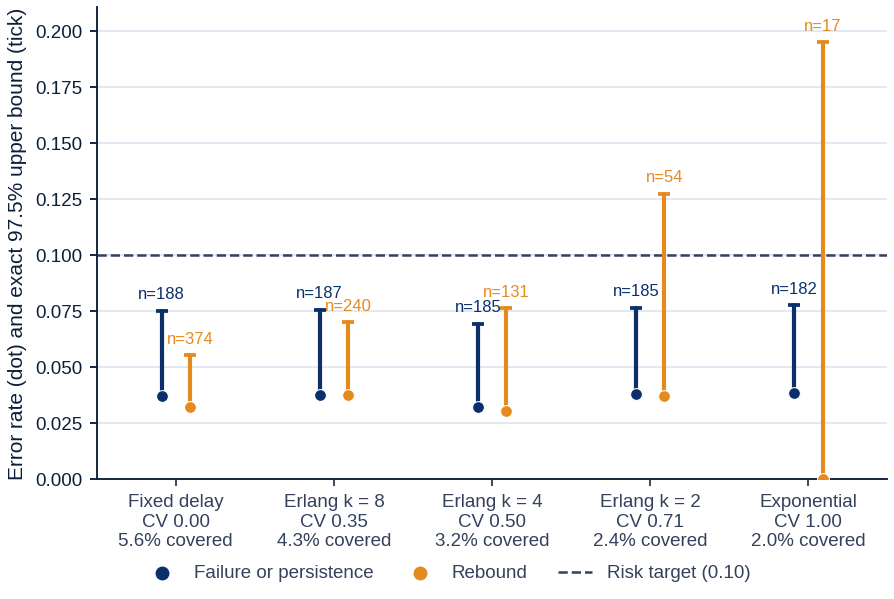

Figure 14: Risk of the frozen policy as latent-period variability increases
matched_k4_train            512/60000  elapsed    1.2s  generated
matched_k4_train           5632/60000  elapsed   14.0s  generated
matched_k4_train          10752/60000  elapsed   26.7s  generated
matched_k4_train          15872/60000  elapsed   39.1s  generated
matched_k4_train          20992/60000  elapsed   51.7s  generated
matched_k4_train          26112/60000  elapsed   64.4s  generated
matched_k4_train          31232/60000  elapsed   77.1s  generated
matched_k4_train          36352/60000  elapsed   89.5s  generated
matched_k4_train          41472/60000  elapsed  101.9s  generated
matched_k4_train          46592/60000  elapsed  114.3s  generated
matched_k4_train          51712/60000  elapsed  126.9s  generated
matched_k4_train          56832/60000  elapsed  139.6s  generated
matched_k4_train          60000/60000  elapsed  148.2s  generated
matched_k4_robust_train     512/30000  elapsed    1.3s  generated


,Test mechanism,Action,"AUROC, trained on fixed delay","AUROC, trained on test mechanism","Average precision, trained on fixed delay","Average precision, trained on test mechanism"
0,Fixed delay (control),Failure or persistence (2 h),0.925,0.925,0.841,0.841
1,Fixed delay (control),Rebound (6 h),0.924,0.924,0.709,0.709
2,"Erlang, k = 4",Failure or persistence (2 h),0.873,0.895,0.808,0.824
3,"Erlang, k = 4",Rebound (6 h),0.899,0.910,0.571,0.597
4,"Exponential, k = 1",Failure or persistence (2 h),0.788,0.866,0.761,0.825
5,"Exponential, k = 1",Rebound (6 h),0.873,0.912,0.327,0.408


In [ ]:
#held-out mechanism cohorts (paired) and the frozen policy
# Same parameters and same assay noise in every cohort (paired design): only the latent-period mechanism changes.
HELD = [("Fixed delay (control)", None, 0.), ("Erlang k = 8", 8, 1/math.sqrt(8)), ("Erlang k = 4", 4, .5),
        ("Erlang k = 2", 2, 1/math.sqrt(2)), ("Exponential (k = 1)", 1, 1.)]
HELD_SEED, HELD_N = 20263000, 10000

def make_sim(k):
    def fn(theta):
        th = theta.clone(); th[:, 4] = th[:, 4].round().clamp(10, 60); th[:, 5] = th[:, 5].round().clamp(10, 60)
        if k is None:
            return core.simulate(th, CFG['full_minutes'], SIM_DEVICE, phys=dict(superinfection=False)).cpu()
        return chain.simulate_chain(th, CFG['full_minutes'], k=(k, k), device=SIM_DEVICE, dt_min=1.).cpu()
    return fn

def generate_cohort_sim(name, seed, n, sim_fn, augmented=False, aug_fraction=None):
    folder = ROOT/'data'/name; folder.mkdir(parents=True, exist_ok=True)
    size = CFG['shard_size']; bounds = torch.tensor(CFG['bounds'])
    master_idx = torch.searchsorted(torch.tensor(CFG['full_minutes']), torch.tensor(CFG['master_minutes']))
    obs_cfg = CFG if aug_fraction is None else {**CFG, 'training_augmentation_fraction': aug_fraction}
    rows, began = [], time.perf_counter(); chain_sha = sha256(CHAIN_PATH)
    for shard_id, start in enumerate(range(0, n, size)):
        stop = min(start + size, n); path = folder/f'shard_{start:06d}_{stop:06d}.pt'
        if path.exists():
            shard = torch.load(path, map_location='cpu', weights_only=True); assert shard['run_id'] == RUN_ID; status = 'reused'
        else:
            s = seed*10000 + shard_id; gen = torch.Generator().manual_seed(s)
            unit = torch.rand(stop - start, 15, generator=gen)
            theta = bounds[:, 0] + unit*(bounds[:, 1] - bounds[:, 0])
            full = sim_fn(theta); clean = full[:, master_idx]
            obs = core.observe(clean, obs_cfg, s + 500000000, scenario={}, augmented=augmented)
            shard = {'run_id': RUN_ID, 'core_sha256': CORE_SHA, 'chain_sha256': chain_sha, 'start': start, 'stop': stop,
                     'theta_unit': unit, 'theta_physical': theta, 'full_values': full, 'clean_master': clean,
                     'label': core.outcomes(full, CFG['full_minutes']), 'endpoint': full[:, -1, 0], **obs}
            for key in ('full_values', 'values', 'theta_physical'): assert torch.isfinite(shard[key]).all(), key
            save_pt(path, shard); status = 'generated'
        rows.append({'cohort': name, 'start': start, 'stop': stop, 'n': stop - start, 'file': path.name,
                     'sha256': sha256(path), 'status': status})
        if shard_id % 10 == 0 or stop == n:
            print(f"{name:<24} {stop:>6}/{n}  elapsed {time.perf_counter() - began:6.1f}s  {status}", flush=True)
    pd.DataFrame(rows).to_csv(folder/'manifest.csv', index=False)
n_cert = len(DATA_FINAL['certification']['label'])
rows, long_rows = [], []
for label, k, cv in HELD:
    name = 'heldout_' + ('fixed' if k is None else f'k{k}')
    generate_cohort_sim(name, HELD_SEED, HELD_N, make_sim(k))
    d = load_cohort(name); inf = infer_data(d); N = len(d['label'])
    pred, _ = core.cascade(inf['action_probability'], THR, CFG, ACT)
    cov = (pred >= 0).float().mean().item()*100; min_sup = CFG['minimum_action_support']*N/n_cert
    row = {"Mechanism": label, "Latent-period CV": round(cv, 2), "Coverage (%)": round(cov, 2)}; reasons = []
    for cls, key, aname in ((3, "Failure", "Failure or persistence"), (1, "Rebound", "Rebound")):
        m = pred == cls; n = int(m.sum()); e = int((d['label'][m] != cls).sum()); u = error_ucb(e, n, .025) if n else np.nan
        sup = n >= min_sup; risk = bool(n > 0 and u <= CFG['risk_target'])
        long_rows.append({"Mechanism": label, "CV": cv, "Action": aname, "Issued": n, "Errors": e,
                          "Error rate": e/n if n else np.nan, "Error upper bound": u})
        row[f"{key} issued"] = n; row[f"{key} error [upper bound] (%)"] = f"{100*e/n:.1f} [{100*u:.2f}]" if n else "-"
        if not sup: reasons.append(f"{key.lower()} support")
        if n > 0 and not risk: reasons.append(f"{key.lower()} risk")
    if cov < CFG['minimum_coverage']*100: reasons.append("coverage")
    row["Out-of-domain flag (%)"] = round(float((~inf['domain'][2]).float().mean())*100, 2)
    row["Gates"] = "Pass" if not reasons else "Fail: " + ", ".join(reasons); rows.append(row)
HELD_TAB, HELD_LONG = pd.DataFrame(rows), pd.DataFrame(long_rows)
HELD_LONG.to_csv(ROOT/'tables'/'heldout_long_form.csv', index=False)
save_table(HELD_TAB, 13, "Frozen policy under a distributed latent period")

# ---- result: risk as a function of latent-period variability ----
fig, ax = new_figure(FIG_W1*1.7, 4.0)
xt = np.arange(len(HELD)); style = {"Failure or persistence": (BLUE["navy"], -.09), "Rebound": (ACCENT["amber"], .09)}
for aname, (c, off) in style.items():
    sub = HELD_LONG[HELD_LONG.Action == aname].reset_index(drop=True)
    for i, r in sub.iterrows():
        if r.Issued == 0: continue
        ax.plot([i + off, i + off], [r["Error rate"], r["Error upper bound"]], color=c, lw=2, solid_capstyle="round", zorder=3)
        ax.scatter([i + off], [r["Error rate"]], s=32, color=c, edgecolor="white", linewidth=.5, zorder=4)
        ax.scatter([i + off], [r["Error upper bound"]], s=30, marker="_", color=c, linewidth=1.8, zorder=4)
        ax.text(i + off, r["Error upper bound"] + .004, f"n={int(r.Issued)}", ha="center", va="bottom", fontsize=8, color=c)
    ax.scatter([], [], s=32, color=c, label=aname)
ax.axhline(CFG['risk_target'], color=BLUE["text"], ls="--", lw=1.2, label=f"Risk target ({CFG['risk_target']:.2f})")
ax.set_xticks(xt); ax.set_xticklabels([f"{lab.split(' (')[0]}\nCV {cv:.2f}\n{c:.1f}% covered"
    for (lab, k, cv), c in zip(HELD, HELD_TAB["Coverage (%)"])])
ax.set_xlim(-.5, len(HELD) - .5); ax.set_ylim(0, max(.2, float(HELD_LONG["Error upper bound"].max())*1.08)); ax.grid(axis="y", zorder=0)
ax.set_ylabel("Error rate (dot) and exact 97.5% upper bound (tick)")
legend_below(fig, ax, ncol=3)
save_figure(fig, 14, "Risk of the frozen policy as latent-period variability increases")

# ---- control: how much of the loss under mechanism shift is the model, and how much is the data? (matched-model comparison) ----
# A model is trained on data from the test mechanism itself, using the same parameters and the same assay noise as the original training cohorts.
SPEC = {x['name']: x for x in COHORT_PLAN}
MATCHED = [("Erlang, k = 4", 4), ("Exponential, k = 1", 1)]
ACTIONS = ((0, "Failure or persistence (2 h)"), (2, "Rebound (6 h)"))
def train_matched(stage, tr_sets, va_set, tag, patience=12, max_epochs=100):
    dev = DEVICE; hour = CFG['hours'][stage]
    feat = lambda d: core.features(d, CFG, hour, STATS[stage]['mean'], STATS[stage]['std'])
    tx = torch.cat([feat(d) for d in tr_sets]).to(dev); tl = torch.cat([d['label'] for d in tr_sets]).to(dev)
    te = ((torch.cat([d['endpoint'] for d in tr_sets]) - END_MEAN)/END_STD).to(dev)
    vx, vl, ve = feat(va_set).to(dev), va_set['label'].to(dev), ((va_set['endpoint'] - END_MEAN)/END_STD).to(dev)
    path = ROOT/'models'/f'matched_{tag}_stage_{stage}.pt'; seed_ = SEED + 7000 + stage*10 + len(tag)
    torch.manual_seed(seed_); model = core.Model(CFG['width'], CFG['mixture_components'], CFG['feature_dims'][stage]).to(dev)
    if path.exists():
        ck = torch.load(path, map_location='cpu', weights_only=True)
        if ck.get('run_id') == RUN_ID and ck.get('done'):
            model.load_state_dict(ck['state_dict']); return model.eval()
    opt = torch.optim.AdamW(model.parameters(), lr=CFG['learning_rate'], weight_decay=1e-4); best, stale = float('inf'), 0; began = time.perf_counter()
    for epoch in range(max_epochs):
        if stale >= patience: break
        order = torch.randperm(len(tx), generator=torch.Generator().manual_seed(seed_ + epoch)).to(dev); model.train()
        for s in range(0, len(order), CFG['train_batch']):
            idx = order[s:s + CFG['train_batch']]; loss = objective(model, tx[idx], tl[idx], te[idx], stage)
            opt.zero_grad(set_to_none=True); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.); opt.step()
        val = validation_loss(model, vx, vl, ve, stage)
        if val < best - 1e-4: best, stale = val, 0; sd = {k_: v_.detach().cpu() for k_, v_ in model.state_dict().items()}
        else: stale += 1
        if epoch % 10 == 0: print(f"  {tag} {hour:g} h epoch {epoch + 1:03d} | validation {val:.4f} | patience {stale:02d} | {(time.perf_counter() - began)/(epoch + 1):.1f}s/epoch", flush=True)
    model.load_state_dict(sd); save_pt(path, {'run_id': RUN_ID, 'done': True, 'state_dict': sd}); return model.eval()

# fixed-delay control: the original model is already matched to this mechanism, so both columns are the same model
d_fix = load_cohort('heldout_fixed'); y_fix = d_fix['label'].numpy(); orig_fix = infer_data(d_fix)['action_probability']; ctrl = []
for stage, aname in ACTIONS:
    p = orig_fix[stage].numpy(); pos = y_fix == ACTION_CLASS[stage]; a, ap_ = roc_auc_score(pos, p), average_precision_score(pos, p)
    ctrl.append({"Test mechanism": "Fixed delay (control)", "Action": aname, "AUROC, trained on fixed delay": a, "AUROC, trained on test mechanism": a,
                 "Average precision, trained on fixed delay": ap_, "Average precision, trained on test mechanism": ap_})

rows = []
for mech, k in MATCHED:
    tag = f'k{k}'; sets = {}
    for base, aug, frac in (('train', True, CFG['training_augmentation_fraction']), ('robust_train', True, CFG['robust_training_augmentation_fraction']),
                            ('validation', False, None)):
        nm = f'matched_{tag}_{base}'; generate_cohort_sim(nm, SPEC[base]['seed'], SPEC[base]['n'], make_sim(k), augmented=aug, aug_fraction=frac)
        sets[base] = load_cohort(nm)
    d_test = load_cohort('heldout_' + tag); y = d_test['label'].numpy(); orig = infer_data(d_test)['action_probability']
    for stage, aname in ACTIONS:
        model = train_matched(stage, [sets['train'], sets['robust_train']], sets['validation'], tag)
        xt_ = core.features(d_test, CFG, CFG['hours'][stage], STATS[stage]['mean'], STATS[stage]['std'])
        pm = torch.sigmoid(predict_model(model, xt_)[4]).numpy(); po = orig[stage].numpy(); pos = y == ACTION_CLASS[stage]
        rows.append({"Test mechanism": mech, "Action": aname, "AUROC, trained on fixed delay": roc_auc_score(pos, po),
                     "AUROC, trained on test mechanism": roc_auc_score(pos, pm), "Average precision, trained on fixed delay": average_precision_score(pos, po),
                     "Average precision, trained on test mechanism": average_precision_score(pos, pm)})
MATCHED_TAB = pd.DataFrame(ctrl + rows).round(3)
save_table(MATCHED_TAB, 15, "Cost of training on the wrong latent-period mechanism")

## Cell 15: Why do rebound calls fall under a distributed latent period?

The previous cell showed that the number of rebound calls falls steeply as latent-period variability increases, while failure calls stay stable. This cell separates three possible reasons: fewer true rebounds, a lower share of true rebounds that receive a call, and lower confidence in those rebounds.

**Identity used.** For a cohort of N cases, the number of rebound calls equals N · π · r / ρ, where π is the prevalence of true rebound, r is the share of true rebounds that receive a rebound call (recall, "caught") and ρ is the precision of rebound calls. Tabulating π, r and ρ, together with the mean calibrated rebound probability among true rebounds, shows which factor drives the change in coverage.

**Columns of Table 14 (one row per mechanism, same cohorts as the previous cell)**

- Rebound prevalence, number of rebound calls issued, share of true rebounds caught, and rebound precision.
- Rebound confidence: the mean, over true rebound cases, of the larger of the calibrated 4 h and 6 h rebound probabilities. This is a summary of how close true rebounds come to the frozen thresholds, not the exact decision rule.
- Failure prevalence and the share of true failures caught, for comparison.

**Output.** Table 14 (prevalence and recall under a distributed latent period). The three factors are plotted relative to the fixed-delay control in the manuscript's Figure 6.

**How to read the results.** Relative to the fixed-delay control, in the reported run the exponential case (k = 1) had a rebound prevalence of 41% of the control value (13.08% to 5.34%), a mean confidence in true rebounds of 39% (0.51 to 0.20), and a recall of 11.5% (27.7% to 3.2%), so that rebound calls fell to 4.5% of the control. On a logarithmic scale, about 29% of the decline in calls is attributable to fewer true rebounds and about 71% to lower recall, with unchanged precision. Failure prevalence rose slightly (33.6% to 39.5%) and the share of failures called fell only from 5.4% to 4.4%, consistent with the stable number of failure calls.

**Notes**
- Outcome labels are recomputed from the trajectories under each mechanism, so the fall in rebound prevalence is itself a consequence of the mechanism change, not a sampling effect. The cohorts share parameter draws and noise seeds.
- The decomposition is arithmetic. It shows which factors account for the change in the number of calls, not why the models become less confident.

In [ ]:
#why does rebound coverage fall? (prevalence vs recall vs confidence)
rows = []
for label, k, cv in HELD:
    name = 'heldout_' + ('fixed' if k is None else f'k{k}'); d = load_cohort(name); inf = infer_data(d)
    pred, _ = core.cascade(inf['action_probability'], THR, CFG, ACT); pred = pred.numpy(); y = d['label'].numpy()
    ap = [p.numpy() for p in inf['action_probability']]
    pos_r, pos_f = y == 1, y == 3; issued_r = pred == 1
    rows.append({"Mechanism": label, "Latent-period CV": round(cv, 2),
                 "Rebound prevalence (%)": 100*pos_r.mean(),
                 "Rebound issued": int(issued_r.sum()),
                 "Rebound caught (%)": 100*(issued_r & pos_r).sum()/pos_r.sum(),
                 "Rebound precision (%)": 100*(issued_r & pos_r).sum()/max(issued_r.sum(), 1),
                 "Rebound confidence, true cases": float(np.maximum(ap[1], ap[2])[pos_r].mean()),
                 "Failure prevalence (%)": 100*pos_f.mean(),
                 "Failure caught (%)": 100*((pred == 3) & pos_f).sum()/pos_f.sum()})
PREV_TAB = pd.DataFrame(rows)
save_table(PREV_TAB.round(2), 14, "Prevalence and recall under a distributed latent period")

Table 14: Prevalence and recall under a distributed latent period


,Mechanism,Latent-period CV,Rebound prevalence (%),Rebound issued,Rebound caught (%),Rebound precision (%),"Rebound confidence, true cases",Failure prevalence (%),Failure caught (%)
0,Fixed delay (control),0.00,13.08,374,27.68,96.79,0.51,33.64,5.38
1,Erlang k = 8,0.35,11.70,240,19.74,96.25,0.45,34.70,5.19
2,Erlang k = 4,0.50,10.38,131,12.24,96.95,0.38,35.66,5.02
3,Erlang k = 2,0.71,8.11,54,6.41,96.30,0.30,37.22,4.78
4,Exponential (k = 1),1.00,5.34,17,3.18,100.00,0.20,39.52,4.43


## Cell 16: Why do rebound calls fall? (figure)

This cell plots the four quantities from Table 14 relative to the fixed-delay control, so that the contribution of each factor to the fall in rebound calls can be compared on one scale.

**What is plotted.** For the fixed-delay control and for Erlang k = 8, 4, 2 and 1 (nominal coefficient of variation 0.35 to 1.00), each series is shown as a percentage of its fixed-delay value:

- the number of rebound calls issued,
- the prevalence of true rebounds,
- the share of true rebounds that receive a rebound call (recall), and
- the mean calibrated confidence assigned to true rebounds (larger of the 4 h and 6 h rebound probabilities).

**How to read it.** The number of calls (navy line) falls fastest. Recall and confidence fall steeply and together, whereas prevalence falls more gently. Because the number of calls equals N · prevalence · recall / precision, and precision stays close to its control value, the gap between the prevalence curve and the calls curve is accounted for mainly by recall. Prevalence therefore explains a smaller part of the decline than recall does.

**Output.** Figure 15 (rebound calls and their determinants, as a percentage of the fixed-delay value).

**Notes**
- Recall and confidence are not independent. Recall falls because the confidence assigned to true rebounds drops below the frozen thresholds, so the figure describes how the decline is distributed across factors, not an independent causal ordering.
- The curves use the paired held-out cohorts from the previous cells. Prevalence changes because outcome labels are recomputed under each mechanism.

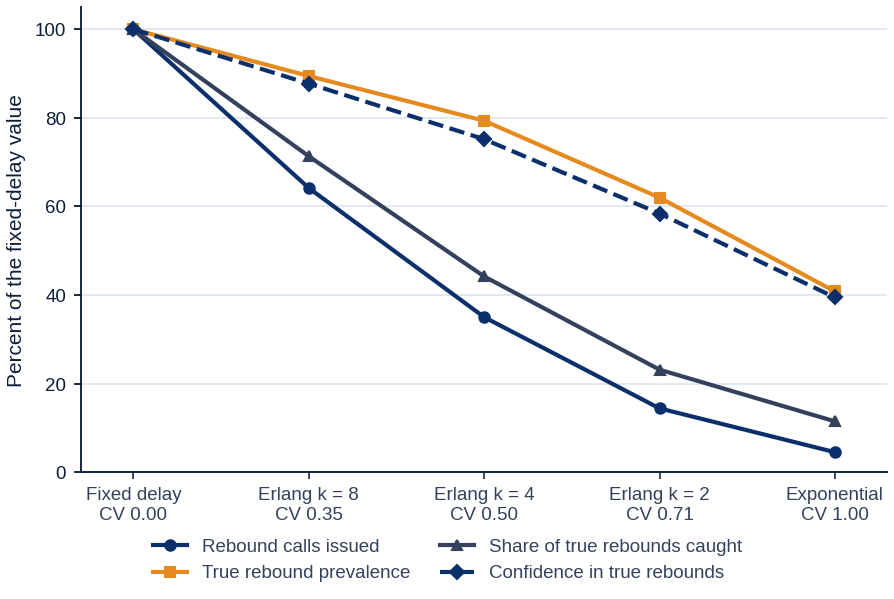

Figure 15: Rebound calls fall mainly because recall and confidence fall, and partly because rebounds become rarer


In [ ]:
#why rebound coverage falls (figure)
T = PREV_TAB.reset_index(drop=True); x = np.arange(len(HELD)); rel = lambda c: 100*T[c]/T[c].iloc[0]
series = [("Rebound calls issued", rel("Rebound issued"), BLUE["navy"], "-", "o"),
          ("True rebound prevalence", rel("Rebound prevalence (%)"), ACCENT["amber"], "-", "s"),
          ("Share of true rebounds caught", rel("Rebound caught (%)"), BLUE["text"], "-", "^"),
          ("Confidence in true rebounds", rel("Rebound confidence, true cases"), BLUE["navy"], "--", "D")]
fig, ax = new_figure(FIG_W1*1.7, 4.0)
for lab, v, c, ls, mk in series: ax.plot(x, v, color=c, ls=ls, marker=mk, lw=2, ms=5, label=lab, zorder=3)
ax.set_xticks(x); ax.set_xticklabels([f"{lab.split(' (')[0]}\nCV {cv:.2f}" for lab, k, cv in HELD])
ax.set_xlim(-.3, len(HELD) - .7); ax.set_ylim(0, 105); ax.grid(axis="y", zorder=0)
ax.set_ylabel("Percent of the fixed-delay value")
legend_below(fig, ax, ncol=2)
save_figure(fig, 15, "Rebound calls fall mainly because recall and confidence fall, and partly because rebounds become rarer")

## Cell 17: Loss and recovery of discrimination under mechanism shift (figure)

This cell plots the matched-model control from Table 15. It shows how much discrimination is lost when the training mechanism (fixed latent period) differs from the test mechanism, and how much of that loss is recovered by training on the test mechanism itself.

**What is plotted.** For each test mechanism (fixed-delay control, Erlang k = 4 and exponential k = 1), the figure shows the AUROC on the held-out cohort of that mechanism for two action heads: failure or persistence at 2 h (navy) and rebound at 6 h (amber). Each pair of points is joined by a line. The open symbol is the model trained on the fixed delay (the original model), and the filled symbol is the model trained on the test mechanism. For the fixed-delay control, the two models are the same, so the symbols coincide.

**How to read it.** The distance from the control level to the open symbol is the discrimination lost under mechanism shift. The line from the open symbol to the filled symbol is the part recovered by matched training. The remaining distance from the filled symbol to the control level is a loss that retraining on the correct mechanism does not remove, which indicates less informative early observations under a variable latent period.

**Output.** Figure 16 (AUROC of the original and matched models on held-out cohorts of the same mechanism).

**Reading the results.** In the reported run, the fixed-delay AUROC was 0.925 for failure at 2 h and 0.924 for rebound at 6 h. Under the original training it fell to 0.873 and 0.899 at k = 4 and to 0.788 and 0.873 at k = 1. Matched training raised AUROC by 0.022 and 0.011 at k = 4 and by 0.078 and 0.038 at k = 1, recovering about 42%, 44%, 57% and 76% of the loss. The matched models did not return to the control level (remaining gaps of 0.030, 0.014, 0.059 and 0.012).

**Notes**
- The matched models are single networks, whereas the original models are three-member ensembles, so the recovery shown may be slightly understated.
- Each comparison rests on a single training run per model. Differences between runs are not captured.
- AUROC is rank-based, so the uncalibrated matched-model probabilities and the calibrated original probabilities are directly comparable.

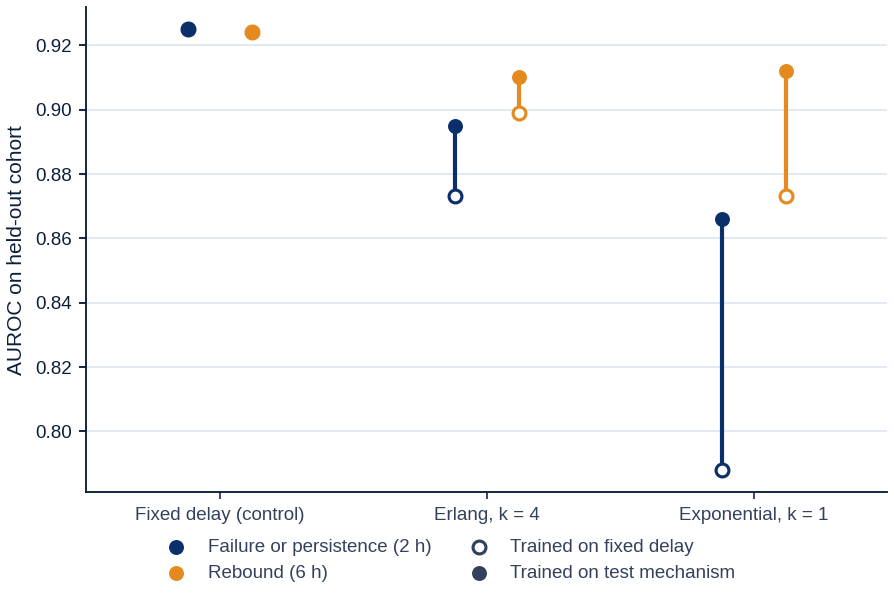

Figure 16: Training on the test mechanism recovers part of the discrimination lost under mechanism shift


In [ ]:
#loss and recovery of discrimination (figure)
mechs = list(MATCHED_TAB["Test mechanism"].unique()); acts = {"Failure or persistence (2 h)": (BLUE["navy"], -.12), "Rebound (6 h)": (ACCENT["amber"], .12)}
fig, ax = new_figure(FIG_W1*1.7, 4.0)
for aname, (c, off) in acts.items():
    sub = MATCHED_TAB[MATCHED_TAB.Action == aname].reset_index(drop=True)
    for i, r in sub.iterrows():
        a, b = r["AUROC, trained on fixed delay"], r["AUROC, trained on test mechanism"]
        ax.plot([i + off]*2, [a, b], color=c, lw=2, zorder=3)
        ax.scatter([i + off], [a], s=38, facecolor="white", edgecolor=c, linewidth=1.5, zorder=4)
        ax.scatter([i + off], [b], s=38, color=c, zorder=4)
    ax.scatter([], [], s=38, color=c, label=aname)
ax.scatter([], [], s=38, facecolor="white", edgecolor=BLUE["text"], linewidth=1.5, label="Trained on fixed delay")
ax.scatter([], [], s=38, color=BLUE["text"], label="Trained on test mechanism")
ax.set_xticks(range(len(mechs))); ax.set_xticklabels(mechs); ax.set_xlim(-.5, len(mechs) - .5); ax.grid(axis="y", zorder=0)
ax.set_ylabel("AUROC on held-out cohort")
legend_below(fig, ax, ncol=2)
save_figure(fig, 16, "Training on the test mechanism recovers part of the discrimination lost under mechanism shift")

## Cell 18: Uncertainty on the matched-model gains (bootstrap over test cases)

This cell quantifies the uncertainty in the AUROC gain from matched training reported in Table 15, which was a point estimate.

**Procedure**

- For each test mechanism (Erlang k = 4 and k = 1) and each action head (failure or persistence at 2 h, rebound at 6 h), the trained matched model and the original model are loaded and scored on the held-out cohort of the same mechanism.
- The test cases are resampled with replacement 500 times (seed 20261002 + 99). In each resample, **both** models are evaluated on the same cases, and the AUROC difference (matched minus original) is recorded. Resamples that contain only one class are skipped.
- The 95% interval is the 2.5th to 97.5th percentile of the 500 paired differences.

**Output.** Table 16 (uncertainty in the discrimination gained by matched training): the point estimate of the AUROC gain with its 95% percentile interval for each mechanism and action.

**How to read it.** An interval that excludes zero means the gain is larger than test-set sampling variability would produce. In the reported run, the gains were +0.022 (95% interval 0.018–0.026) for failure and +0.011 (0.006–0.015) for rebound at k = 4, and +0.078 (0.070–0.086) and +0.038 (0.030–0.048) at k = 1. All four intervals exclude zero.

**Notes**
- The intervals reflect **test-set sampling only**. They do not capture variability between training runs, because each matched model is a single run with a single seed.
- The fixed-delay control is not included, because its gain is zero by construction (the original and matched models are the same).
- The trained matched models are loaded from checkpoints, so this cell does not retrain them.

In [ ]:
# uncertainty on the matched-model gains (bootstrap over test cases)
B = 500; rng = np.random.default_rng(SEED + 99); out = []
for mech, k in MATCHED:
    tag = f'k{k}'; d_test = load_cohort('heldout_' + tag); y = d_test['label'].numpy(); orig = infer_data(d_test)['action_probability']
    sets = {b: load_cohort(f'matched_{tag}_{b}') for b in ('train', 'robust_train', 'validation')}
    for stage, aname in ACTIONS:
        model = train_matched(stage, [sets['train'], sets['robust_train']], sets['validation'], tag)
        xt_ = core.features(d_test, CFG, CFG['hours'][stage], STATS[stage]['mean'], STATS[stage]['std'])
        pm = torch.sigmoid(predict_model(model, xt_)[4]).numpy(); po = orig[stage].numpy(); pos = y == ACTION_CLASS[stage]; diffs = []
        for _ in range(B):
            idx = rng.integers(0, len(pos), len(pos))
            if pos[idx].all() or not pos[idx].any(): continue
            diffs.append(roc_auc_score(pos[idx], pm[idx]) - roc_auc_score(pos[idx], po[idx]))
        lo, hi = np.percentile(diffs, [2.5, 97.5])
        out.append({"Test mechanism": mech, "Action": aname, "AUROC gain": roc_auc_score(pos, pm) - roc_auc_score(pos, po),
                    "95% interval, low": lo, "95% interval, high": hi})
save_table(pd.DataFrame(out).round(3), 16, "Uncertainty in the discrimination gained by matched training")

Table 16: Uncertainty in the discrimination gained by matched training


,Test mechanism,Action,AUROC gain,"95% interval, low","95% interval, high"
0,"Erlang, k = 4",Failure or persistence (2 h),0.022,0.018,0.026
1,"Erlang, k = 4",Rebound (6 h),0.011,0.006,0.015
2,"Exponential, k = 1",Failure or persistence (2 h),0.078,0.070,0.086
3,"Exponential, k = 1",Rebound (6 h),0.038,0.030,0.048
